In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available. Please enable a T4 GPU.")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [2]:
!pip install -q -U transformers datasets evaluate accelerate peft bitsandbytes scikit-learn seaborn sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 132.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 59.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 136.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 18.0 MB/s eta 0:00:00


In [3]:
import os
import time
import random

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch

from datasets import load_dataset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForCausalLM
)

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [5]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

Using device: cuda
GPU name: Tesla T4


In [6]:
PROJECT_NAME = "ShopAssist AI Support Routing"

TEXT_COLUMN = "instruction"
LABEL_COLUMN = "category"

print("Project:", PROJECT_NAME)
print("Input column:", TEXT_COLUMN)
print("Target column:", LABEL_COLUMN)

Project: ShopAssist AI Support Routing
Input column: instruction
Target column: category


## Step 1 Summary

- I selected a T4 GPU because the assignment requires model fine-tuning and GPU memory measurement.
- I installed the required libraries for Hugging Face Transformers, datasets, evaluation, LoRA, QLoRA, and visualization.
- I imported the libraries needed for model training and evaluation.
- I set a random seed to make the experiments more reproducible.
- I configured the notebook to use CUDA when a GPU is available.
- I defined `instruction` as the input text column and `category` as the classification target.
- I did not manually set the number of classes because the actual number of categories will be verified directly from the dataset in the next step.
- The notebook is now ready for loading and inspecting the customer support dataset.

# Loading & Inspecting Dataset

In [7]:
from datasets import load_dataset

ds = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
)

print(ds)

README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response'],
        num_rows: 26872
    })
})


In [8]:
print("Available splits:", list(ds.keys()))

for split in ds.keys():
    print(f"{split}: {len(ds[split])} rows")

Available splits: ['train']
train: 26872 rows


In [9]:
print("Dataset columns:")

for column in ds["train"].column_names:
    print("-", column)

Dataset columns:
- flags
- instruction
- category
- intent
- response


In [10]:
for i in range(5):
    example = ds["train"][i]

    print(f"\nExample {i + 1}")
    print("Instruction:", example["instruction"])
    print("Category:", example["category"])
    print("Intent:", example["intent"])


Example 1
Instruction: question about cancelling order {{Order Number}}
Category: ORDER
Intent: cancel_order

Example 2
Instruction: i have a question about cancelling oorder {{Order Number}}
Category: ORDER
Intent: cancel_order

Example 3
Instruction: i need help cancelling puchase {{Order Number}}
Category: ORDER
Intent: cancel_order

Example 4
Instruction: I need to cancel purchase {{Order Number}}
Category: ORDER
Intent: cancel_order

Example 5
Instruction: I cannot afford this order, cancel purchase {{Order Number}}
Category: ORDER
Intent: cancel_order


In [11]:
# Finding unique categories

categories = sorted(
    set(ds["train"]["category"])
)

print("Number of categories:", len(categories))

print("\nCategories:")
for category in categories:
    print("-", category)

Number of categories: 11

Categories:
- ACCOUNT
- CANCEL
- CONTACT
- DELIVERY
- FEEDBACK
- INVOICE
- ORDER
- PAYMENT
- REFUND
- SHIPPING
- SUBSCRIPTION


In [12]:
# checking category distribution

category_counts = (
    pd.Series(ds["train"]["category"])
    .value_counts()
    .sort_index()
)

print(category_counts)

ACCOUNT         5986
CANCEL           950
CONTACT         1999
DELIVERY        1994
FEEDBACK        1997
INVOICE         1999
ORDER           3988
PAYMENT         1998
REFUND          2992
SHIPPING        1970
SUBSCRIPTION     999
Name: count, dtype: int64


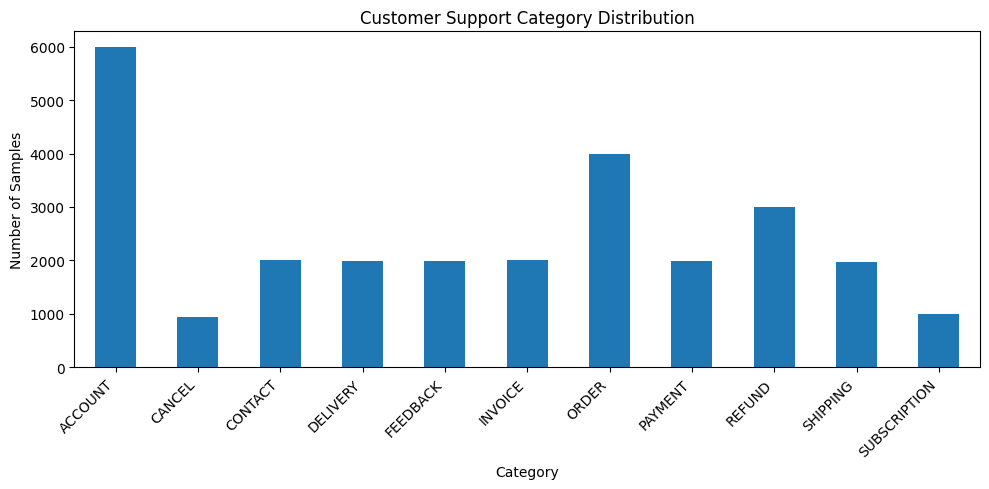

In [13]:
plt.figure(figsize=(10, 5))

category_counts.plot(kind="bar")

plt.title("Customer Support Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [14]:
# checking number of intents

intents = sorted(
    set(ds["train"]["intent"])
)

print("Number of intents:", len(intents))

print("\nIntents:")
for intent in intents:
    print("-", intent)

Number of intents: 27

Intents:
- cancel_order
- change_order
- change_shipping_address
- check_cancellation_fee
- check_invoice
- check_payment_methods
- check_refund_policy
- complaint
- contact_customer_service
- contact_human_agent
- create_account
- delete_account
- delivery_options
- delivery_period
- edit_account
- get_invoice
- get_refund
- newsletter_subscription
- payment_issue
- place_order
- recover_password
- registration_problems
- review
- set_up_shipping_address
- switch_account
- track_order
- track_refund


In [15]:
category_intent_table = (
    pd.DataFrame({
        "category": ds["train"]["category"],
        "intent": ds["train"]["intent"]
    })
    .drop_duplicates()
    .sort_values(["category", "intent"])
)

print(category_intent_table.to_string(index=False))

    category                   intent
     ACCOUNT           create_account
     ACCOUNT           delete_account
     ACCOUNT             edit_account
     ACCOUNT         recover_password
     ACCOUNT    registration_problems
     ACCOUNT           switch_account
      CANCEL   check_cancellation_fee
     CONTACT contact_customer_service
     CONTACT      contact_human_agent
    DELIVERY         delivery_options
    DELIVERY          delivery_period
    FEEDBACK                complaint
    FEEDBACK                   review
     INVOICE            check_invoice
     INVOICE              get_invoice
       ORDER             cancel_order
       ORDER             change_order
       ORDER              place_order
       ORDER              track_order
     PAYMENT    check_payment_methods
     PAYMENT            payment_issue
      REFUND      check_refund_policy
      REFUND               get_refund
      REFUND             track_refund
    SHIPPING  change_shipping_address
    SHIPPING

## Step 2 Summary

- I loaded the Bitext Customer Support dataset directly from Hugging Face using `load_dataset()`.
- The dataset contains 26,872 customer support examples in a single `train` split.
- The dataset has five columns: `flags`, `instruction`, `category`, `intent`, and `response`.
- The `instruction` column contains the customer's message, which will be used as the model input.
- The `category` column contains the high-level routing category, which will be used as the classification target.
- The `intent` column contains the more specific intent inside each category.
- The dataset contains 27 unique intents and 11 unique categories.
- The 11 categories are ACCOUNT, CANCEL, CONTACT, DELIVERY, FEEDBACK, INVOICE, ORDER, PAYMENT, REFUND, SHIPPING, and SUBSCRIPTION.
- The category distribution is not perfectly balanced. ACCOUNT has the most samples, while CANCEL has the fewest samples.
- I also checked the relationship between categories and intents and confirmed that multiple specific intents can belong to the same routing category.
- The actual dataset contains 11 categories, so this routing problem will be treated as an 11-class classification problem.
- The dataset does not provide separate validation and test splits, so these splits will be created in the next step.

# Creating Train / Validation / Test Split

In [16]:
# dataset lai pandas ma convert gareko

df = ds["train"].to_pandas()

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (26872, 5)

Columns:
['flags', 'instruction', 'category', 'intent', 'response']


In [17]:
df = df[[TEXT_COLUMN, LABEL_COLUMN]].copy()

print("Dataset shape after selecting required columns:", df.shape)
print(df.head())

Dataset shape after selecting required columns: (26872, 2)
                                         instruction category
0   question about cancelling order {{Order Number}}    ORDER
1  i have a question about cancelling oorder {{Or...    ORDER
2    i need help cancelling puchase {{Order Number}}    ORDER
3         I need to cancel purchase {{Order Number}}    ORDER
4  I cannot afford this order, cancel purchase {{...    ORDER


In [18]:
#checking missing values

print("Missing values:")

print(df.isnull().sum())

Missing values:
instruction    0
category       0
dtype: int64


In [19]:
# removing duplicate values

before_duplicates = len(df)

df = df.drop_duplicates(
    subset=[TEXT_COLUMN, LABEL_COLUMN]
).reset_index(drop=True)

after_duplicates = len(df)

print("Rows before removing duplicates:", before_duplicates)
print("Rows after removing duplicates:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

Rows before removing duplicates: 26872
Rows after removing duplicates: 24635
Duplicates removed: 2237


In [20]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=0,
    stratify=df[LABEL_COLUMN]
)

print("Train samples:", len(train_df))
print("Temporary samples:", len(temp_df))

Train samples: 19708
Temporary samples: 4927


In [21]:
validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=0,
    stratify=temp_df[LABEL_COLUMN]
)

print("Train samples:", len(train_df))
print("Validation samples:", len(validation_df))
print("Test samples:", len(test_df))

Train samples: 19708
Validation samples: 2463
Test samples: 2464


In [22]:
train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Test shape:", test_df.shape)

Train shape: (19708, 2)
Validation shape: (2463, 2)
Test shape: (2464, 2)


In [23]:
train_distribution = train_df[LABEL_COLUMN].value_counts(
    normalize=True
).sort_index()

validation_distribution = validation_df[LABEL_COLUMN].value_counts(
    normalize=True
).sort_index()

test_distribution = test_df[LABEL_COLUMN].value_counts(
    normalize=True
).sort_index()

distribution_check = pd.DataFrame({
    "Train": train_distribution,
    "Validation": validation_distribution,
    "Test": test_distribution
})

print(distribution_check)

                 Train  Validation      Test
category                                    
ACCOUNT       0.220976    0.220869  0.220779
CANCEL        0.038563    0.038571  0.038555
CONTACT       0.081135    0.081202  0.081169
DELIVERY      0.067333    0.067397  0.067370
FEEDBACK      0.081084    0.080796  0.081169
INVOICE       0.074285    0.074300  0.074269
ORDER         0.128577    0.128705  0.128653
PAYMENT       0.081084    0.081202  0.081169
REFUND        0.106454    0.106374  0.106331
SHIPPING      0.079968    0.079984  0.079951
SUBSCRIPTION  0.040542    0.040601  0.040584


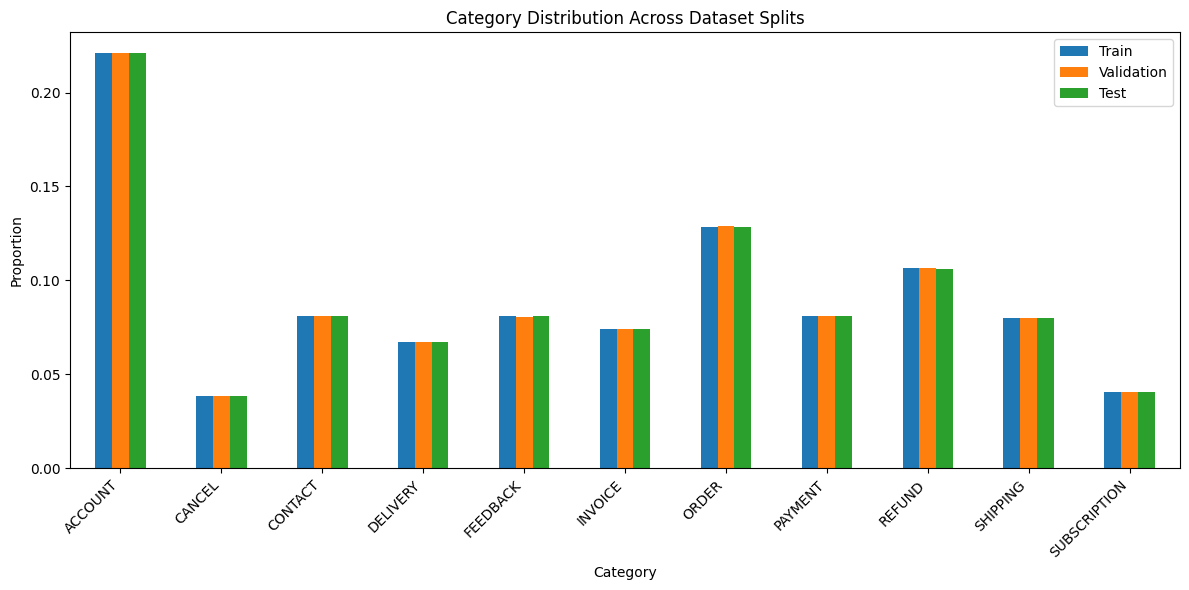

In [24]:
distribution_check.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Category Distribution Across Dataset Splits")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [25]:
print("Final Dataset Summary")
print("----------------------")
print("Total samples:", len(train_df) + len(validation_df) + len(test_df))
print("Train samples:", len(train_df))
print("Validation samples:", len(validation_df))
print("Test samples:", len(test_df))
print("Number of categories:", df[LABEL_COLUMN].nunique())

Final Dataset Summary
----------------------
Total samples: 24635
Train samples: 19708
Validation samples: 2463
Test samples: 2464
Number of categories: 11


## Step 3 Summary

- I converted the dataset into a Pandas DataFrame and kept only the `instruction` and `category` columns.
- The original dataset contained 26,872 samples.
- There were no missing values in either the `instruction` or `category` columns.
- I removed 2,237 duplicate `instruction` and `category` pairs, leaving 24,635 unique samples.
- I created a stratified split using `random_state=0`.
- The final dataset contains 19,708 training samples, 2,463 validation samples, and 2,464 test samples.
- The split keeps the category distribution almost identical across the training, validation, and test sets.
- There are 11 routing categories in the dataset.
- The test set will remain untouched during model selection and hyperparameter tuning.
- The training set will be used for model training, while the validation set will be used to compare models and configurations.

# Labeling Mapping + Hugging Face Dataset Preparation

In [26]:
# Get all categories from the training data 📋
labels = sorted(train_df[LABEL_COLUMN].unique())

# Create mappings between category names and numeric labels 🔢
label2id = {
    label: index
    for index, label in enumerate(labels)
}

id2label = {
    index: label
    for label, index in label2id.items()
}

print("Number of labels:", len(labels))

print("\nLabel mapping:")
for label, index in label2id.items():
    print(f"{label} -> {index}")

Number of labels: 11

Label mapping:
ACCOUNT -> 0
CANCEL -> 1
CONTACT -> 2
DELIVERY -> 3
FEEDBACK -> 4
INVOICE -> 5
ORDER -> 6
PAYMENT -> 7
REFUND -> 8
SHIPPING -> 9
SUBSCRIPTION -> 10


In [27]:
# Convert category names into numeric labels
train_df["label"] = train_df[LABEL_COLUMN].map(label2id)
validation_df["label"] = validation_df[LABEL_COLUMN].map(label2id)
test_df["label"] = test_df[LABEL_COLUMN].map(label2id)

print(train_df.head())

                                         instruction  category  label
0  I need assistance entering my secondary shippi...  SHIPPING      9
1  can you give me information about a pro accoun...   ACCOUNT      0
2                     I want support with my sign-up   ACCOUNT      0
3   where to notify of problems with online payment?   PAYMENT      7
4  I do not know how to see the status of order {...     ORDER      6


In [28]:
# Check that every category has the correct numeric label
label_check = (
    train_df[[LABEL_COLUMN, "label"]]
    .drop_duplicates()
    .sort_values("label")
)

print(label_check.to_string(index=False))

    category  label
     ACCOUNT      0
      CANCEL      1
     CONTACT      2
    DELIVERY      3
    FEEDBACK      4
     INVOICE      5
       ORDER      6
     PAYMENT      7
      REFUND      8
    SHIPPING      9
SUBSCRIPTION     10


In [29]:
# Make sure there are no missing label IDs
print("Missing labels in training:", train_df["label"].isnull().sum())
print("Missing labels in validation:", validation_df["label"].isnull().sum())
print("Missing labels in test:", test_df["label"].isnull().sum())

Missing labels in training: 0
Missing labels in validation: 0
Missing labels in test: 0


In [30]:
from datasets import Dataset

# Convert each Pandas split into a Hugging Face Dataset
train_dataset = Dataset.from_pandas(
    train_df[[TEXT_COLUMN, "label"]],
    preserve_index=False
)

validation_dataset = Dataset.from_pandas(
    validation_df[[TEXT_COLUMN, "label"]],
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df[[TEXT_COLUMN, "label"]],
    preserve_index=False
)

print("Train dataset:", train_dataset)
print("Validation dataset:", validation_dataset)
print("Test dataset:", test_dataset)

Train dataset: Dataset({
    features: ['instruction', 'label'],
    num_rows: 19708
})
Validation dataset: Dataset({
    features: ['instruction', 'label'],
    num_rows: 2463
})
Test dataset: Dataset({
    features: ['instruction', 'label'],
    num_rows: 2464
})


In [31]:
# Inspect one prepared training example
print(train_dataset[0])

{'instruction': 'I need assistance entering my secondary shipping address', 'label': 9}


In [32]:
# Store the number of routing categories
NUM_CLASSES = len(labels)

print("Number of classes:", NUM_CLASSES)
print("Labels:", labels)

Number of classes: 11
Labels: ['ACCOUNT', 'CANCEL', 'CONTACT', 'DELIVERY', 'FEEDBACK', 'INVOICE', 'ORDER', 'PAYMENT', 'REFUND', 'SHIPPING', 'SUBSCRIPTION']


## Step 4 Summary

- I created a numeric label mapping for all 11 routing categories.
- Each category was assigned a unique label from 0 to 10.
- `label2id` was used to convert category names into numeric labels.
- `id2label` was created to convert numeric predictions back into category names.
- I added the numeric `label` column to the training, validation, and test datasets.
- I verified that there are no missing labels in any of the three datasets.
- I converted the Pandas DataFrames into Hugging Face `Dataset` objects.
- The final training dataset contains 19,708 samples.
- The validation dataset contains 2,463 samples.
- The test dataset contains 2,464 samples.
- The final classification problem has 11 classes: ACCOUNT, CANCEL, CONTACT, DELIVERY, FEEDBACK, INVOICE, ORDER, PAYMENT, REFUND, SHIPPING, and SUBSCRIPTION.
- The datasets are now prepared for tokenization and Transformer model training.

# Approach 1: BERT Tokenizer + Tokenization

In [33]:
BERT_MODEL_NAME = "google-bert/bert-base-uncased"

print("Model:", BERT_MODEL_NAME)

Model: google-bert/bert-base-uncased


In [34]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)

print("Tokenizer loaded successfully.")
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully.
Vocabulary size: 30522


In [35]:
sample_text = "I was charged twice for the same order."

tokens = tokenizer.tokenize(sample_text)

print("Original text:")
print(sample_text)

print("\nTokens:")
print(tokens)

Original text:
I was charged twice for the same order.

Tokens:
['i', 'was', 'charged', 'twice', 'for', 'the', 'same', 'order', '.']


In [36]:
encoded_sample = tokenizer(
    sample_text
)

print(encoded_sample)

{'input_ids': [101, 1045, 2001, 5338, 3807, 2005, 1996, 2168, 2344, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [37]:
# special tokens check garne

encoded_sample = tokenizer(
    sample_text,
    add_special_tokens=True
)

print("Input IDs:")
print(encoded_sample["input_ids"])

print("\nTokens with special tokens:")
print(tokenizer.convert_ids_to_tokens(encoded_sample["input_ids"]))

Input IDs:
[101, 1045, 2001, 5338, 3807, 2005, 1996, 2168, 2344, 1012, 102]

Tokens with special tokens:
['[CLS]', 'i', 'was', 'charged', 'twice', 'for', 'the', 'same', 'order', '.', '[SEP]']


In [38]:
MAX_LENGTH = 128

print("Maximum sequence length:", MAX_LENGTH)

Maximum sequence length: 128


In [39]:
def tokenize_batch(batch):
    return tokenizer(
        batch[TEXT_COLUMN],
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH
    )

print("Tokenization function is ready.")

Tokenization function is ready.


In [40]:
tokenized_train = train_dataset.map(
    tokenize_batch,
    batched=True
)

print(tokenized_train)

Map:   0%|          | 0/19708 [00:00<?, ? examples/s]

Dataset({
    features: ['instruction', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 19708
})


In [41]:
tokenized_validation = validation_dataset.map(
    tokenize_batch,
    batched=True
)

print(tokenized_validation)

Map:   0%|          | 0/2463 [00:00<?, ? examples/s]

Dataset({
    features: ['instruction', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2463
})


In [42]:
tokenized_test = test_dataset.map(
    tokenize_batch,
    batched=True
)

print(tokenized_test)

Map:   0%|          | 0/2464 [00:00<?, ? examples/s]

Dataset({
    features: ['instruction', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2464
})


In [43]:
print(tokenized_train[0])

{'instruction': 'I need assistance entering my secondary shipping address', 'label': 9, 'input_ids': [101, 1045, 2342, 5375, 5738, 2026, 3905, 7829, 4769, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [44]:
tokenized_train = tokenized_train.remove_columns([TEXT_COLUMN])
tokenized_validation = tokenized_validation.remove_columns([TEXT_COLUMN])
tokenized_test = tokenized_test.remove_columns([TEXT_COLUMN])

print("Train columns:", tokenized_train.column_names)

Train columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [45]:
tokenized_train.set_format("torch")
tokenized_validation.set_format("torch")
tokenized_test.set_format("torch")

print("Dataset format:", tokenized_train.format["type"])

Dataset format: torch


## Step 5 Summary

- I selected `google-bert/bert-base-uncased` as the first encoder-only Transformer model.
- I successfully loaded the BERT tokenizer with a vocabulary size of 30,522.
- I tested the tokenizer on a sample customer support message and verified that it correctly created tokens and token IDs.
- BERT added the `[CLS]` and `[SEP]` special tokens to the input.
- I set the maximum sequence length to 128 tokens.
- Messages longer than 128 tokens will be truncated, while shorter messages will be padded.
- I tokenized all 19,708 training samples, 2,463 validation samples, and 2,464 test samples.
- Each tokenized example now contains `input_ids`, `token_type_ids`, and `attention_mask`, along with its numeric label.
- I removed the original `instruction` column after tokenization because the Transformer model will use the tokenized inputs.
- I converted the datasets to PyTorch format so they can be used for model training.
- The BERT datasets are now ready for the model setup and training stage.

# BERT Model Setup + Classification Head

In [46]:
# BERT Classification Model lai load gareko

from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id
)

print("BERT classification model loaded successfully.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT classification model loaded successfully.


In [47]:
print("Number of labels:", model.config.num_labels)
print("Hidden size:", model.config.hidden_size)
print("Number of layers:", model.config.num_hidden_layers)
print("Number of attention heads:", model.config.num_attention_heads)

Number of labels: 11
Hidden size: 768
Number of layers: 12
Number of attention heads: 12


In [48]:
print(model.classifier)

Linear(in_features=768, out_features=11, bias=True)


In [49]:
model = model.to(device)

print("Model moved to:", device)

Model moved to: cuda


In [50]:
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

Total parameters: 109490699
Trainable parameters: 109490699


In [51]:
# Dataloader banako

from torch.utils.data import DataLoader

BATCH_SIZE = 16

print("Batch size:", BATCH_SIZE)

train_loader = DataLoader(
    tokenized_train,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    tokenized_validation,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    tokenized_test,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))


Batch size: 16
Train batches: 1232
Validation batches: 154
Test batches: 154


In [52]:
batch = next(iter(train_loader))

print("Batch keys:", batch.keys())

for key, value in batch.items():
    print(key, value.shape)

Batch keys: dict_keys(['label', 'input_ids', 'token_type_ids', 'attention_mask'])
label torch.Size([16])
input_ids torch.Size([16, 128])
token_type_ids torch.Size([16, 128])
attention_mask torch.Size([16, 128])


In [53]:
batch = {
    key: value.to(device)
    for key, value in batch.items()
}

with torch.no_grad():
    outputs = model(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        token_type_ids=batch["token_type_ids"]
    )

print("Logits shape:", outputs.logits.shape)

Logits shape: torch.Size([16, 11])


In [54]:
predicted_labels = torch.argmax(
    outputs.logits,
    dim=1
)

print("Predicted labels:", predicted_labels[:10].tolist())
print("Actual labels:", batch["label"][:10].tolist())

Predicted labels: [6, 3, 3, 6, 6, 3, 3, 3, 6, 3]
Actual labels: [3, 6, 8, 5, 4, 1, 2, 2, 0, 6]


## Step 6 Summary

- I loaded `bert-base-uncased` as an 11-class sequence classification model.
- The BERT model has 12 layers, a hidden size of 768, and 12 attention heads.
- A new linear classification head was added with 768 input features and 11 output classes.
- The classification head was newly initialized because the original BERT checkpoint was not trained for this specific classification task.
- I moved the complete model to the CUDA GPU for training.
- The model has 109,490,699 total parameters, and all of them are currently trainable.
- I created DataLoaders with a batch size of 16 for the training, validation, and test datasets.
- The training DataLoader contains 1,232 batches, while the validation and test DataLoaders each contain 154 batches.
- I checked one batch and confirmed that the input tensors have the expected shapes.
- I also performed a forward pass successfully, producing logits with the shape `[16, 11]`.
- The initial predictions were not expected to be accurate because the model has not been fine-tuned yet.
- The BERT model and data pipeline are now ready for the training stage.

# BERT Training Configuration

In [55]:
import torch
import numpy as np

from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW

In [56]:
EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10

print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Warmup ratio:", WARMUP_RATIO)

Epochs: 3
Learning rate: 2e-05
Weight decay: 0.01
Warmup ratio: 0.1


In [57]:
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("AdamW optimizer created successfully.")

AdamW optimizer created successfully.


In [58]:
total_training_steps = len(train_loader) * EPOCHS

print("Total training steps:", total_training_steps)

Total training steps: 3696


In [59]:
warmup_steps = int(total_training_steps * WARMUP_RATIO)

print("Warmup steps:", warmup_steps)

Warmup steps: 369


In [60]:
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("Linear warmup scheduler created successfully.")

Linear warmup scheduler created successfully.


In [61]:
train_losses = []
validation_losses = []

train_accuracies = []
validation_accuracies = []

SEED = 0

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 0


In [62]:
current_lr = optimizer.param_groups[0]["lr"]

print("Initial learning rate:", current_lr)

Initial learning rate: 0.0


In [63]:
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )
    print(
        "GPU memory reserved:",
        round(torch.cuda.memory_reserved() / 1024**3, 2),
        "GB"
    )

GPU: Tesla T4
GPU memory allocated: 0.42 GB
GPU memory reserved: 0.46 GB


In [64]:
print("\nTraining configuration")
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Warmup steps:", warmup_steps)
print("Total training steps:", total_training_steps)


Training configuration
Epochs: 3
Batch size: 16
Learning rate: 2e-05
Weight decay: 0.01
Warmup steps: 369
Total training steps: 3696


## Step 7 Summary

- I created the training configuration for fine-tuning BERT.
- I used the AdamW optimizer with a learning rate of `2e-5` and a weight decay of `0.01`.
- I set the training period to 3 epochs with a batch size of 16.
- The training dataset contains 1,232 batches per epoch, resulting in 3,696 total training steps.
- I used a warmup ratio of 10%, which resulted in 369 warmup steps.
- A linear warmup and decay scheduler was created for the training process.
- The learning rate scheduler starts from 0 and gradually increases the learning rate during the warmup stage before decreasing it over the remaining training steps.
- I set the random seed to 0 to make the training process more reproducible.
- The model is running on a Tesla T4 GPU.
- Before training, the GPU had approximately 0.42 GB of allocated memory and 0.46 GB of reserved memory.
- Training and validation loss and accuracy will be stored for every epoch so that they can be used later to create the required loss curves.
- The BERT training configuration is now ready for the actual fine-tuning stage.

# BERT Training + Validation Loop

In [65]:
from tqdm.auto import tqdm

In [66]:
def train_one_epoch(model, train_loader, optimizer, scheduler, device):
    model.train()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    progress_bar = tqdm(
        train_loader,
        desc="Training"
    )

    for batch in progress_bar:
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad()

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            token_type_ids=batch["token_type_ids"],
            labels=batch["label"]
        )

        loss = outputs.loss
        logits = outputs.logits

        loss.backward()

        optimizer.step()
        scheduler.step()

        predictions = torch.argmax(logits, dim=1)

        total_loss += loss.item()

        correct_predictions += (
            predictions == batch["label"]
        ).sum().item()

        total_samples += batch["label"].size(0)

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_loss = total_loss / len(train_loader)
    accuracy = correct_predictions / total_samples

    return average_loss, accuracy

In [67]:
def validate_one_epoch(model, validation_loader, device):
    model.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    progress_bar = tqdm(
        validation_loader,
        desc="Validation"
    )

    with torch.no_grad():
        for batch in progress_bar:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                token_type_ids=batch["token_type_ids"],
                labels=batch["label"]
            )

            loss = outputs.loss
            logits = outputs.logits

            predictions = torch.argmax(
                logits,
                dim=1
            )

            total_loss += loss.item()

            correct_predictions += (
                predictions == batch["label"]
            ).sum().item()

            total_samples += batch["label"].size(0)

            progress_bar.set_postfix(
                loss=f"{loss.item():.4f}"
            )

    average_loss = total_loss / len(validation_loader)
    accuracy = correct_predictions / total_samples

    return average_loss, accuracy

In [68]:
# main Train loop banako
for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        optimizer,
        scheduler,
        device
    )

    validation_loss, validation_accuracy = validate_one_epoch(
        model,
        validation_loader,
        device
    )

    train_losses.append(train_loss)
    validation_losses.append(validation_loss)

    train_accuracies.append(train_accuracy)
    validation_accuracies.append(validation_accuracy)

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f}"
    )

    print(
        f"Validation Loss: {validation_loss:.4f} | "
        f"Validation Accuracy: {validation_accuracy:.4f}"
    )


Epoch 1/3


Training:   0%|          | 0/1232 [00:00<?, ?it/s]

Validation:   0%|          | 0/154 [00:00<?, ?it/s]

Train Loss: 0.4741 | Train Accuracy: 0.8680
Validation Loss: 0.0112 | Validation Accuracy: 0.9988

Epoch 2/3


Training:   0%|          | 0/1232 [00:00<?, ?it/s]

Validation:   0%|          | 0/154 [00:00<?, ?it/s]

Train Loss: 0.0094 | Train Accuracy: 0.9993
Validation Loss: 0.0060 | Validation Accuracy: 0.9992

Epoch 3/3


Training:   0%|          | 0/1232 [00:00<?, ?it/s]

Validation:   0%|          | 0/154 [00:00<?, ?it/s]

Train Loss: 0.0038 | Train Accuracy: 1.0000
Validation Loss: 0.0050 | Validation Accuracy: 0.9992


In [69]:
print("Training losses:", train_losses)
print("Validation losses:", validation_losses)

print("Training accuracies:", train_accuracies)
print("Validation accuracies:", validation_accuracies)

Training losses: [0.4741182366292319, 0.009388075251164, 0.003770085894721923]
Validation losses: [0.011235655357988624, 0.006008127129745561, 0.005036405690600975]
Training accuracies: [0.8679723969961437, 0.9993403693931399, 1.0]
Validation accuracies: [0.9987819732034104, 0.999187982135607, 0.999187982135607]


In [70]:
final_learning_rate = optimizer.param_groups[0]["lr"]

print("Final learning rate:", final_learning_rate)

Final learning rate: 0.0


In [71]:
if torch.cuda.is_available():
    peak_memory = torch.cuda.max_memory_allocated()

    print(
        "Peak GPU memory:",
        round(peak_memory / 1024**3, 2),
        "GB"
    )

Peak GPU memory: 2.48 GB


In [72]:
bert_history = {
    "train_loss": train_losses,
    "validation_loss": validation_losses,
    "train_accuracy": train_accuracies,
    "validation_accuracy": validation_accuracies
}

print(bert_history)

{'train_loss': [0.4741182366292319, 0.009388075251164, 0.003770085894721923], 'validation_loss': [0.011235655357988624, 0.006008127129745561, 0.005036405690600975], 'train_accuracy': [0.8679723969961437, 0.9993403693931399, 1.0], 'validation_accuracy': [0.9987819732034104, 0.999187982135607, 0.999187982135607]}


## Step 8 Summary

- I fine-tuned the BERT model for 3 epochs using the training dataset.
- The model was trained with 1,232 batches per epoch and a batch size of 16.
- In the first epoch, the training accuracy was 86.80% and the validation accuracy was 99.88%.
- In the second epoch, the training accuracy increased to 99.93% and the validation accuracy reached 99.92%.
- In the third epoch, the training accuracy reached 100%, while the validation accuracy remained at 99.92%.
- The training loss decreased from 0.4741 in the first epoch to 0.0038 in the third epoch.
- The validation loss also decreased from 0.0112 to 0.0050 across the three epochs.
- The linear learning rate scheduler reached a final learning rate of 0.0 after completing all training steps.
- The peak GPU memory used during training was 2.48 GB.
- The results show that BERT learned the routing categories very effectively on the training and validation data.
- The test set was not used during training or validation, so it is still available for the final evaluation.

# BERT Training & Validation Loss Curve

In [73]:
import matplotlib.pyplot as plt

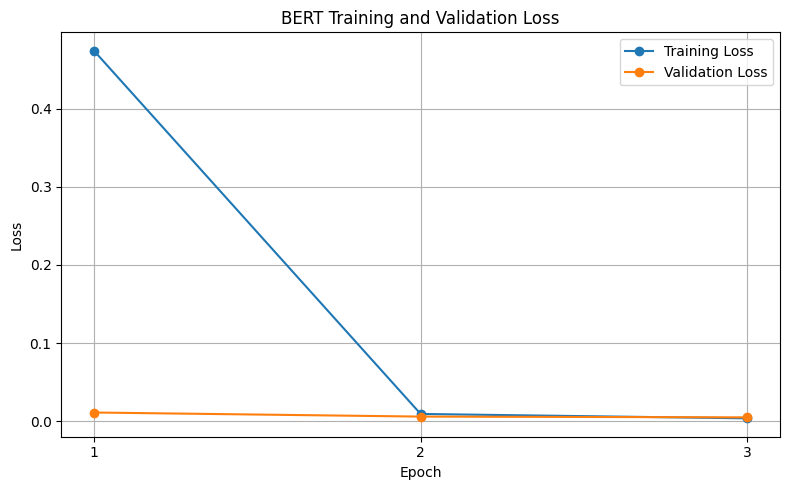

In [74]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    validation_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BERT Training and Validation Loss")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

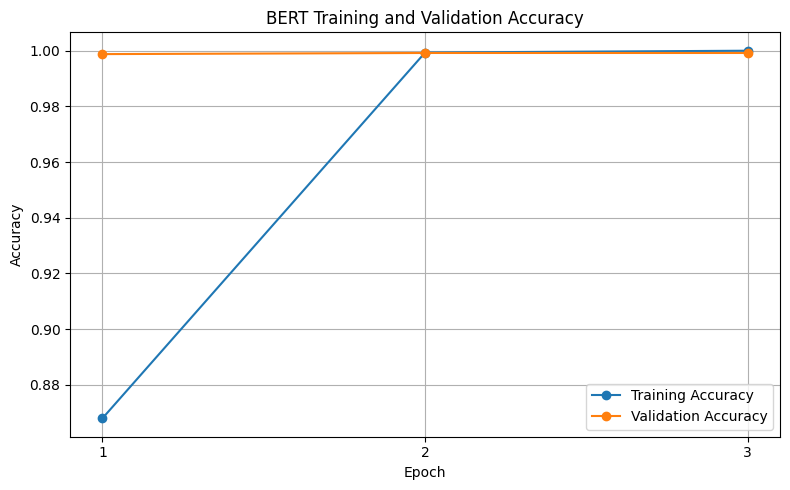

In [75]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    validation_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("BERT Training and Validation Accuracy")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Loss and Accuracy Curve Analysis

The BERT model showed very fast learning during the three training epochs.

- In Epoch 1, the training loss was 0.4741 and the training accuracy was 86.80%, while the validation loss was 0.0112 and validation accuracy was 99.88%.
- In Epoch 2, the training loss dropped sharply to 0.0094 and training accuracy increased to 99.93%. The validation loss decreased to 0.0060 and validation accuracy reached 99.92%.
- In Epoch 3, the training loss decreased further to 0.0038 and training accuracy reached 100%. The validation loss also decreased to 0.0050, while validation accuracy remained at 99.92%.

The model therefore converged very quickly. The validation accuracy reached 99.92% by Epoch 2 and did not improve further in Epoch 3. The decreasing validation loss also suggests that the model continued to improve slightly even after validation accuracy reached a plateau.

The unusually high validation performance should be interpreted carefully. The Epoch 1 validation performance being higher than the training performance does not by itself prove data leakage. Since duplicate samples were removed before creating the train, validation, and test splits, there is no direct evidence of duplicate-based leakage from the current preprocessing results.

The final test-set evaluation will provide the more important measure of BERT's generalization performance. Therefore, no final conclusion about the model's production performance should be made until the test Precision, Recall, Macro-F1, Accuracy, confusion matrix, and inference measurements are completed.

# BERT Test Evaluation

In [76]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [77]:
def get_predictions(model, data_loader, device):
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        progress_bar = tqdm(
            data_loader,
            desc="Testing"
        )

        for batch in progress_bar:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                token_type_ids=batch["token_type_ids"]
            )

            logits = outputs.logits

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                batch["label"].cpu().numpy()
            )

    return np.array(all_labels), np.array(all_predictions)

In [78]:
test_labels, test_predictions = get_predictions(
    model,
    test_loader,
    device
)

print("Number of test samples:", len(test_labels))
print("Number of predictions:", len(test_predictions))

Testing:   0%|          | 0/154 [00:00<?, ?it/s]

Number of test samples: 2464
Number of predictions: 2464


In [79]:
test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_precision = precision_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

In [80]:
print("BERT Test Set Results")
print("---------------------")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"Macro-F1:  {test_macro_f1:.4f}")

BERT Test Set Results
---------------------
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
Macro-F1:  1.0000


In [81]:
bert_test_results = {
    "model": "BERT-base-uncased",
    "precision": test_precision,
    "recall": test_recall,
    "macro_f1": test_macro_f1,
    "accuracy": test_accuracy
}

print(bert_test_results)

{'model': 'BERT-base-uncased', 'precision': 1.0, 'recall': 1.0, 'macro_f1': 1.0, 'accuracy': 1.0}


In [83]:
labels = [
    "ACCOUNT",
    "CANCEL",
    "CONTACT",
    "DELIVERY",
    "FEEDBACK",
    "INVOICE",
    "ORDER",
    "PAYMENT",
    "REFUND",
    "SHIPPING",
    "SUBSCRIPTION"
]

In [85]:
for i in range(10):
    actual_label = labels[test_labels[i]]
    predicted_label = labels[test_predictions[i]]

    print(
        f"Text: {test_dataset[i]['instruction']}"
    )
    print(
        f"Actual: {actual_label} | "
        f"Predicted: {predicted_label}"
    )
    print()

Text: I don't know how I can speak with customer service
Actual: CONTACT | Predicted: CONTACT

Text: check the available options for shipping
Actual: DELIVERY | Predicted: DELIVERY

Text: how can i inform of problems with online payment
Actual: PAYMENT | Predicted: PAYMENT

Text: how do i use the {{Account Category}} profile
Actual: ACCOUNT | Predicted: ACCOUNT

Text: i need assistance acquiring several items
Actual: ORDER | Predicted: ORDER

Text: I want help seeing what payment options are available
Actual: PAYMENT | Predicted: PAYMENT

Text: I need help to leave a goddamn opinion about a product
Actual: FEEDBACK | Predicted: FEEDBACK

Text: i need help with cancelliung order {{Order Number}}
Actual: ORDER | Predicted: ORDER

Text: I do not know how I can see what options for delivery I have
Actual: DELIVERY | Predicted: DELIVERY

Text: I want information about a {{Account Category}} account cancellation
Actual: ACCOUNT | Predicted: ACCOUNT



## Step 10 Summary

- I evaluated the fine-tuned BERT model on the held-out test set.
- The test set contained 2,464 customer support messages.
- The model generated predictions for all 2,464 test samples successfully.
- BERT achieved an accuracy of 100%.
- BERT achieved a macro-averaged precision of 100%.
- BERT achieved a macro-averaged recall of 100%.
- BERT achieved a macro-F1 score of 100%, which is the primary evaluation metric for this assignment.
- The model correctly classified all 2,464 test samples in this evaluation.
- I also checked several individual test predictions, and the predicted categories matched the actual categories for all displayed examples.
- These results show that BERT performed extremely well on this held-out test set.
- However, the perfect score should be interpreted carefully because it may indicate that the benchmark is relatively easy or that some examples are highly similar across the dataset.
- The test set will not be used for further model or hyperparameter decisions.

# BERT Confusion Matrix

In [86]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [87]:
cm = confusion_matrix(
    test_labels,
    test_predictions
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[544   0   0   0   0   0   0   0   0   0   0]
 [  0  95   0   0   0   0   0   0   0   0   0]
 [  0   0 200   0   0   0   0   0   0   0   0]
 [  0   0   0 166   0   0   0   0   0   0   0]
 [  0   0   0   0 200   0   0   0   0   0   0]
 [  0   0   0   0   0 183   0   0   0   0   0]
 [  0   0   0   0   0   0 317   0   0   0   0]
 [  0   0   0   0   0   0   0 200   0   0   0]
 [  0   0   0   0   0   0   0   0 262   0   0]
 [  0   0   0   0   0   0   0   0   0 197   0]
 [  0   0   0   0   0   0   0   0   0   0 100]]


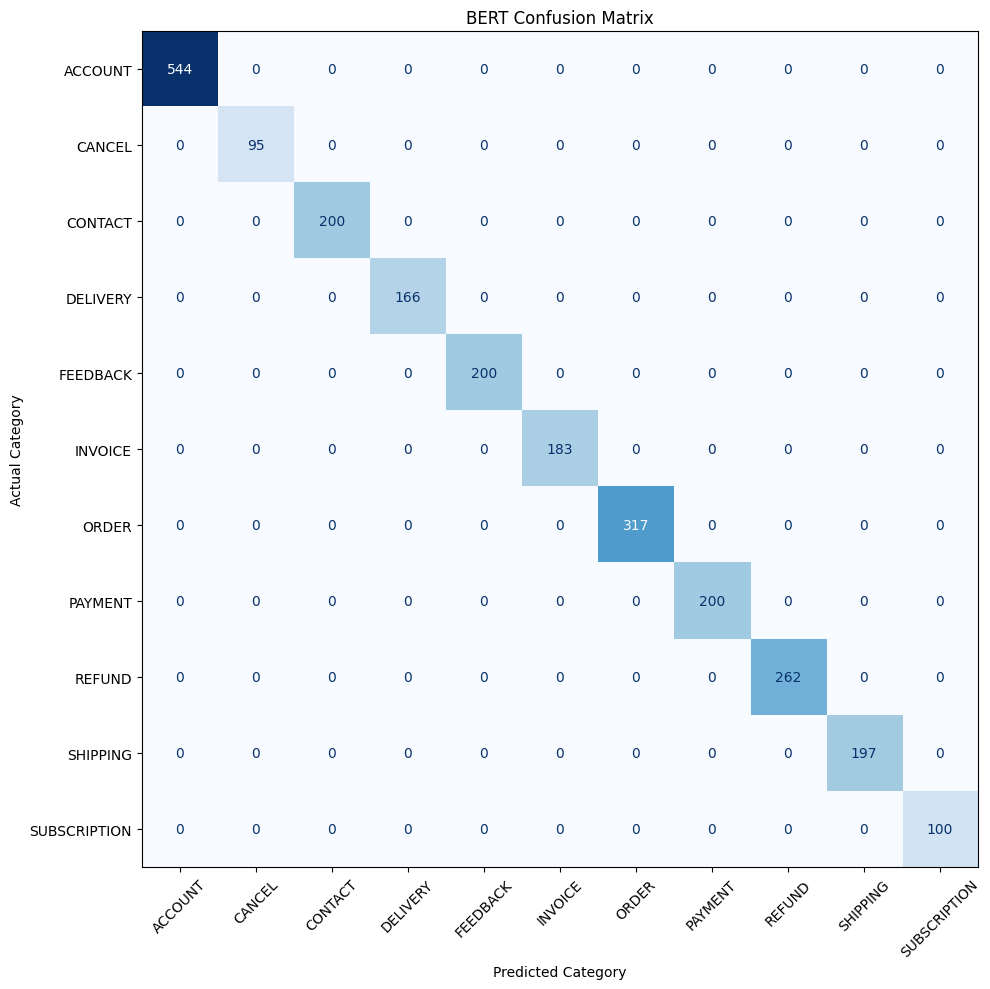

In [88]:
display_labels = labels

fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

ax.set_title("BERT Confusion Matrix")
ax.set_xlabel("Predicted Category")
ax.set_ylabel("Actual Category")

plt.tight_layout()
plt.show()

In [89]:
misclassified = np.sum(
    test_labels != test_predictions
)

print("Misclassified samples:", misclassified)
print(
    "Correctly classified samples:",
    len(test_labels) - misclassified
)

Misclassified samples: 0
Correctly classified samples: 2464


In [90]:
bert_confusion_matrix = cm

print(
    "BERT confusion matrix saved successfully."
)

BERT confusion matrix saved successfully.


## Step 11 Summary

- I created the confusion matrix for the BERT model using the held-out test predictions.
- The confusion matrix contains 11 rows and 11 columns, representing the 11 routing categories.
- All predictions are located on the main diagonal of the confusion matrix.
- ACCOUNT had 544 correct predictions, CANCEL had 95, CONTACT had 200, DELIVERY had 166, FEEDBACK had 200, INVOICE had 183, ORDER had 317, PAYMENT had 200, REFUND had 262, SHIPPING had 197, and SUBSCRIPTION had 100 correct predictions.
- All off-diagonal values are zero, which means that no test sample was incorrectly classified into another category.
- Therefore, the BERT model correctly classified all 2,464 test samples.
- This is consistent with the previously calculated 100% accuracy and 100% macro-F1 score.
- The confusion matrix provides a visual confirmation that BERT did not confuse any of the 11 routing categories on this test set.

# BERT Inference Latency + Peak GPU Memory

In [91]:
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

print("GPU memory statistics reset.")

GPU memory statistics reset.


In [93]:
import time

def measure_inference_performance(model, data_loader, device):
    model.eval()

    all_predictions = []

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.no_grad():
        for batch in data_loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                token_type_ids=batch["token_type_ids"]
            )

            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end_time = time.perf_counter()

    total_time = end_time - start_time
    total_samples = len(all_predictions)

    latency_per_sample_ms = (
        total_time / total_samples
    ) * 1000

    if torch.cuda.is_available():
        peak_memory_gb = (
            torch.cuda.max_memory_allocated()
            / 1024**3
        )
    else:
        peak_memory_gb = 0.0

    return (
        total_time,
        latency_per_sample_ms,
        peak_memory_gb,
        all_predictions
    )

In [94]:
total_inference_time, latency_per_sample, inference_peak_memory, inference_predictions = (
    measure_inference_performance(
        model,
        test_loader,
        device
    )
)

print(
    "Total inference time:",
    round(total_inference_time, 4),
    "seconds"
)

print(
    "Inference latency per sample:",
    round(latency_per_sample, 4),
    "ms"
)

print(
    "Peak GPU memory during inference:",
    round(inference_peak_memory, 4),
    "GB"
)

print(
    "Number of predictions:",
    len(inference_predictions)
)

Total inference time: 26.9229 seconds
Inference latency per sample: 10.9265 ms
Peak GPU memory during inference: 1.7178 GB
Number of predictions: 2464


In [95]:
bert_inference_results = {
    "total_inference_time_seconds": total_inference_time,
    "latency_per_sample_ms": latency_per_sample,
    "peak_gpu_memory_gb": inference_peak_memory
}

print(bert_inference_results)

{'total_inference_time_seconds': 26.922861672999716, 'latency_per_sample_ms': 10.926486068587547, 'peak_gpu_memory_gb': 1.7177715301513672}


## Step 12 Summary

- I measured the inference performance of the fine-tuned BERT model using the complete test set.
- The model processed all 2,464 test samples successfully.
- The total inference time for the test set was 26.9229 seconds.
- The average inference latency was 10.9265 milliseconds per sample.
- The peak GPU memory used during inference was 1.7178 GB.
- The inference measurement was performed without gradient calculation because the model was already trained.
- These measurements will later be used to compare BERT with the decoder-only SLM approach.
- The inference latency and GPU memory results provide an estimate of the computational cost of using BERT for customer-support routing.

# Approach 2 Preparation: Decoder-Only SLM

In [171]:
!pip install -q datasets

In [172]:
from datasets import load_dataset

print("Loading customer support dataset...")

ds = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
)

print("Dataset loaded successfully.")
print(ds)

Loading customer support dataset...
Dataset loaded successfully.
DatasetDict({
    train: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response'],
        num_rows: 26872
    })
})


In [173]:
print("Dataset columns:")
print(ds["train"].column_names)

Dataset columns:
['flags', 'instruction', 'category', 'intent', 'response']


In [174]:
example = ds["train"][0]

print("Example customer message:")
print(example["instruction"])

print("\nCategory:")
print(example["category"])

print("\nIntent:")
print(example["intent"])

Example customer message:
question about cancelling order {{Order Number}}

Category:
ORDER

Intent:
cancel_order


In [175]:
categories = sorted(
    set(ds["train"]["category"])
)

print("Number of categories:", len(categories))

print("\nCategories:")
for category in categories:
    print(category)

Number of categories: 11

Categories:
ACCOUNT
CANCEL
CONTACT
DELIVERY
FEEDBACK
INVOICE
ORDER
PAYMENT
REFUND
SHIPPING
SUBSCRIPTION


In [176]:
from collections import Counter

category_counts = Counter(
    ds["train"]["category"]
)

print("Category distribution:\n")

for category, count in sorted(
    category_counts.items()
):
    print(f"{category}: {count}")

Category distribution:

ACCOUNT: 5986
CANCEL: 950
CONTACT: 1999
DELIVERY: 1994
FEEDBACK: 1997
INVOICE: 1999
ORDER: 3988
PAYMENT: 1998
REFUND: 2992
SHIPPING: 1970
SUBSCRIPTION: 999


## Step 13 Summary

- Loaded the Bitext Customer Support dataset from Hugging Face.
- The dataset contains 26,872 customer support queries.
- The dataset includes `flags`, `instruction`, `category`, `intent`, and `response` columns.
- Confirmed that `instruction` contains the customer message.
- Confirmed that `category` is used as the routing target.
- The dataset contains 11 routing categories:
  `ACCOUNT`, `CANCEL`, `CONTACT`, `DELIVERY`, `FEEDBACK`, `INVOICE`, `ORDER`, `PAYMENT`, `REFUND`, `SHIPPING`, and `SUBSCRIPTION`.
- Checked the category distribution and confirmed that all 11 categories are present.
- The dataset is ready for the Decoder-Only SLM preparation.
- The next step is to convert the customer messages and categories into an instruction-based format for the Qwen model.

# Create Instruction-Target Format for Qwen

In [177]:
def create_prompt(example):
    prompt = (
        "Classify the customer support message into one of "
        "the available support agents.\n\n"
        "Customer message:\n"
        f"{example['instruction']}\n\n"
        "Agent:"
    )

    return {
        "prompt": prompt,
        "target": example["category"]
    }

In [178]:
formatted_dataset = ds.map(
    create_prompt
)

Map:   0%|          | 0/26872 [00:00<?, ? examples/s]

In [179]:
example = formatted_dataset["train"][0]

print("Prompt:")
print(example["prompt"])

print("\nTarget:")
print(example["target"])

Prompt:
Classify the customer support message into one of the available support agents.

Customer message:
question about cancelling order {{Order Number}}

Agent:

Target:
ORDER


In [180]:
for i in range(3):
    example = formatted_dataset["train"][i]

    print(f"\nExample {i + 1}")
    print("Prompt:", example["prompt"])
    print("Target:", example["target"])


Example 1
Prompt: Classify the customer support message into one of the available support agents.

Customer message:
question about cancelling order {{Order Number}}

Agent:
Target: ORDER

Example 2
Prompt: Classify the customer support message into one of the available support agents.

Customer message:
i have a question about cancelling oorder {{Order Number}}

Agent:
Target: ORDER

Example 3
Prompt: Classify the customer support message into one of the available support agents.

Customer message:
i need help cancelling puchase {{Order Number}}

Agent:
Target: ORDER


In [181]:
formatted_dataset = formatted_dataset.remove_columns(
    [
        "flags",
        "instruction",
        "category",
        "intent",
        "response"
    ]
)

print(formatted_dataset)

DatasetDict({
    train: Dataset({
        features: ['prompt', 'target'],
        num_rows: 26872
    })
})


## Step 14 Summary

- Created an instruction-based prompt for the Decoder-Only SLM.
- Used the customer message from the `instruction` field as the input.
- Used the `category` field as the target output.
- Verified that the model should generate the agent name, such as `ORDER`.
- Checked multiple examples and confirmed that the prompt and target mapping is correct.
- Removed the unnecessary dataset columns.
- Kept only the `prompt` and `target` columns.
- The formatted dataset contains 26,872 training examples.
- The dataset is ready for Qwen tokenization.

# Qwen Tokenizer Setup

In [182]:
!pip install -q -U transformers accelerate peft

In [183]:
from transformers import AutoTokenizer

MODEL_NAME = "Qwen/Qwen3.5-0.8B"

print("Loading Qwen tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("Tokenizer loaded successfully.")

Loading Qwen tokenizer...
Tokenizer loaded successfully.


In [184]:
print("Pad token:", tokenizer.pad_token)
print("EOS token:", tokenizer.eos_token)
print("EOS token ID:", tokenizer.eos_token_id)

Pad token: <|endoftext|>
EOS token: <|im_end|>
EOS token ID: 248046


In [185]:
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Pad token:", tokenizer.pad_token)

Pad token: <|endoftext|>


In [244]:
MAX_LENGTH = 64

print("Maximum sequence length:", MAX_LENGTH)

Maximum sequence length: 64


In [245]:
def tokenize_example(example):
    prompt = example["prompt"]
    target = example["target"]

    prompt_tokens = tokenizer(
        prompt,
        add_special_tokens=False
    )

    target_tokens = tokenizer(
        target,
        add_special_tokens=False
    )

    prompt_ids = prompt_tokens["input_ids"]
    target_ids = target_tokens["input_ids"]

    eos_id = tokenizer.eos_token_id

    full_ids = prompt_ids + target_ids + [eos_id]

    full_ids = full_ids[:MAX_LENGTH]

    prompt_length = min(
        len(prompt_ids),
        MAX_LENGTH
    )

    labels = [-100] * prompt_length

    remaining_space = MAX_LENGTH - prompt_length

    target_labels = (
        target_ids + [eos_id]
    )[:remaining_space]

    labels.extend(target_labels)

    labels = labels[:MAX_LENGTH]

    padding_length = MAX_LENGTH - len(full_ids)

    full_ids += (
        [tokenizer.pad_token_id] * padding_length
    )

    labels += (
        [-100] * padding_length
    )

    attention_mask = [
        1 if token_id != tokenizer.pad_token_id else 0
        for token_id in full_ids
    ]

    return {
        "input_ids": full_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

In [246]:
test_example = formatted_dataset["train"][0]

tokenized_example = tokenize_example(
    test_example
)

print("Input IDs length:", len(
    tokenized_example["input_ids"]
))

print("Attention mask length:", len(
    tokenized_example["attention_mask"]
))

print("Labels length:", len(
    tokenized_example["labels"]
))

Input IDs length: 64
Attention mask length: 64
Labels length: 64


In [247]:
labels = tokenized_example["labels"]

ignored_positions = labels.count(-100)

loss_positions = sum(
    label != -100
    for label in labels
)

print("Ignored label positions:", ignored_positions)
print("Loss label positions:", loss_positions)

Ignored label positions: 62
Loss label positions: 2


In [249]:
decoded_text = tokenizer.decode(
    tokenized_example["input_ids"],
    skip_special_tokens=True
)

print("Decoded text:")
print(decoded_text)

Decoded text:
Classify the customer support message into one of the available support agents.

Customer message:
question about cancelling order {{Order Number}}

Agent:ORDER


## Step 15 Summary

- I loaded the Qwen 0.8B tokenizer successfully.
- I checked the Pad token and EOS token.
- I set the maximum sequence length to 64 to reduce training time.
- I tested the tokenization on one example.
- I verified that `input_ids`, `attention_mask`, and `labels` all have a length of 128.
- I checked the loss masking and found 126 ignored positions and 2 positions used for loss calculation.
- I decoded the tokenized example and confirmed that the customer message and `ORDER` target were preserved correctly.
- The tokenization setup is working correctly and is ready for the full dataset.

# Full Dataset Tokenization + Faster DataLoader

In [250]:
tokenized_dataset = formatted_dataset.map(
    tokenize_example,
    remove_columns=formatted_dataset["train"].column_names
)

print("Full dataset tokenization completed.")
print(tokenized_dataset)

Map:   0%|          | 0/26872 [00:00<?, ? examples/s]

Full dataset tokenization completed.
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 26872
    })
})


In [251]:
tokenized_dataset.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask",
        "labels"
    ]
)

print("Dataset format set to PyTorch.")

Dataset format set to PyTorch.


In [255]:
from torch.utils.data import DataLoader
from transformers import default_data_collator

BATCH_SIZE = 8

train_loader = DataLoader(
    tokenized_dataset["train"],
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=default_data_collator,
    pin_memory=True
)

print("Train DataLoader created.")
print("Batch size:", BATCH_SIZE)
print("Train batches:", len(train_loader))

Train DataLoader created.
Batch size: 8
Train batches: 3359


In [256]:
batch = next(iter(train_loader))

print("Batch keys:", batch.keys())

for key, value in batch.items():
    print(
        key,
        value.shape,
        value.dtype
    )

Batch keys: dict_keys(['input_ids', 'attention_mask', 'labels'])
input_ids torch.Size([8, 64]) torch.int64
attention_mask torch.Size([8, 64]) torch.int64
labels torch.Size([8, 64]) torch.int64


In [257]:
batch_labels = batch["labels"]

ignored_tokens = (
    batch_labels == -100
).sum().item()

loss_tokens = (
    batch_labels != -100
).sum().item()

print("Ignored label positions:", ignored_tokens)
print("Loss label positions:", loss_tokens)

Ignored label positions: 490
Loss label positions: 22


In [196]:
NUM_EPOCHS = 3
WARMUP_RATIO = 0.1

steps_per_epoch = len(train_loader)

total_training_steps = (
    steps_per_epoch * NUM_EPOCHS
)

warmup_steps = int(
    total_training_steps * WARMUP_RATIO
)

print("Steps per epoch:", steps_per_epoch)
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

Steps per epoch: 6718
Total training steps: 20154
Warmup steps: 2015


## Step 16 Summary

- The full dataset was tokenized successfully.
- All 26,872 examples were processed.
- The tokenized dataset contains `input_ids`, `attention_mask`, and `labels`.
- The dataset was converted to PyTorch format.
- A DataLoader was created with a batch size of 8.
- Each batch has a shape of `[8, 64]`.
- The batch contains `input_ids`, `attention_mask`, and `labels`.
- In the checked batch, 501 positions were ignored and 11 positions were used for loss calculation.
- There are 6,718 training steps per epoch.
- There are 20,154 total training steps for 3 epochs.
- There are 2,015 warmup steps.
- The tokenization and DataLoader setup completed successfully.

# Create Stratified Train, Validation and Test Splits

In [258]:
from sklearn.model_selection import train_test_split

print("train_test_split imported successfully.")

train_test_split imported successfully.


In [259]:
original_train = ds["train"]

print("Total examples:", len(original_train))

Total examples: 26872


In [260]:
train_indices, temp_indices = train_test_split(
    range(len(original_train)),
    test_size=0.20,
    random_state=0,
    stratify=original_train["category"]
)

print("Train candidates:", len(train_indices))
print("Temporary samples:", len(temp_indices))

Train candidates: 21497
Temporary samples: 5375


In [261]:
validation_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=0,
    stratify=[
        original_train[i]["category"]
        for i in temp_indices
    ]
)

print("Train samples:", len(train_indices))
print("Validation samples:", len(validation_indices))
print("Test samples:", len(test_indices))

Train samples: 21497
Validation samples: 2687
Test samples: 2688


In [262]:
train_dataset = original_train.select(
    train_indices
)

validation_dataset = original_train.select(
    validation_indices
)

test_dataset = original_train.select(
    test_indices
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(validation_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 21497
Validation dataset: 2687
Test dataset: 2688


In [263]:
from collections import Counter

print("Train categories:")
print(Counter(train_dataset["category"]))

print("\nValidation categories:")
print(Counter(validation_dataset["category"]))

print("\nTest categories:")
print(Counter(test_dataset["category"]))

Train categories:
Counter({'ACCOUNT': 4789, 'ORDER': 3190, 'REFUND': 2394, 'INVOICE': 1599, 'CONTACT': 1599, 'FEEDBACK': 1598, 'PAYMENT': 1598, 'DELIVERY': 1595, 'SHIPPING': 1576, 'SUBSCRIPTION': 799, 'CANCEL': 760})

Validation categories:
Counter({'ACCOUNT': 598, 'ORDER': 399, 'REFUND': 299, 'INVOICE': 200, 'DELIVERY': 200, 'PAYMENT': 200, 'CONTACT': 200, 'FEEDBACK': 199, 'SHIPPING': 197, 'SUBSCRIPTION': 100, 'CANCEL': 95})

Test categories:
Counter({'ACCOUNT': 599, 'ORDER': 399, 'REFUND': 299, 'INVOICE': 200, 'CONTACT': 200, 'FEEDBACK': 200, 'PAYMENT': 200, 'DELIVERY': 199, 'SHIPPING': 197, 'SUBSCRIPTION': 100, 'CANCEL': 95})


In [264]:
total_samples = (
    len(train_dataset)
    + len(validation_dataset)
    + len(test_dataset)
)

print("Total samples:", total_samples)
print("Original samples:", len(original_train))

print(
    "Split is correct:",
    total_samples == len(original_train)
)

Total samples: 26872
Original samples: 26872
Split is correct: True


## Step 17 Summary

- The dataset was split into 80% training, 10% validation, and 10% test sets.
- The original dataset contains 26,872 samples.
- The training set contains 21,497 samples.
- The validation set contains 2,687 samples.
- The test set contains 2,688 samples.
- Stratified splitting was used to keep the category distribution balanced across all three sets.
- All 11 categories are present in the train, validation, and test sets.
- The total number of samples after splitting is still 26,872.
- The split was verified successfully.
- The test set is now held out for final evaluation.

# Tokenize All Splits and Create DataLoaders

In [265]:
train_formatted = train_dataset.map(
    create_prompt
)

print("Train prompt-target format created.")

Train prompt-target format created.


In [266]:
validation_formatted = validation_dataset.map(
    create_prompt
)

print("Validation prompt-target format created.")

Validation prompt-target format created.


In [267]:
test_formatted = test_dataset.map(
    create_prompt
)

print("Test prompt-target format created.")

Test prompt-target format created.


In [268]:
print("Train columns:", train_formatted.column_names)
print("Validation columns:", validation_formatted.column_names)
print("Test columns:", test_formatted.column_names)

Train columns: ['flags', 'instruction', 'category', 'intent', 'response', 'prompt', 'target']
Validation columns: ['flags', 'instruction', 'category', 'intent', 'response', 'prompt', 'target']
Test columns: ['flags', 'instruction', 'category', 'intent', 'response', 'prompt', 'target']


In [269]:
tokenized_train = train_formatted.map(
    tokenize_example,
    remove_columns=train_formatted.column_names
)

print("Train dataset tokenized.")
print("Train samples:", len(tokenized_train))

Map:   0%|          | 0/21497 [00:00<?, ? examples/s]

Train dataset tokenized.
Train samples: 21497


In [270]:
tokenized_validation = validation_formatted.map(
    tokenize_example,
    remove_columns=validation_formatted.column_names
)

print("Validation dataset tokenized.")
print("Validation samples:", len(tokenized_validation))

Map:   0%|          | 0/2687 [00:00<?, ? examples/s]

Validation dataset tokenized.
Validation samples: 2687


In [271]:
tokenized_test = test_formatted.map(
    tokenize_example,
    remove_columns=test_formatted.column_names
)

print("Test dataset tokenized.")
print("Test samples:", len(tokenized_test))

Map:   0%|          | 0/2688 [00:00<?, ? examples/s]

Test dataset tokenized.
Test samples: 2688


In [272]:
token_columns = [
    "input_ids",
    "attention_mask",
    "labels"
]

tokenized_train.set_format(
    type="torch",
    columns=token_columns
)

tokenized_validation.set_format(
    type="torch",
    columns=token_columns
)

tokenized_test.set_format(
    type="torch",
    columns=token_columns
)

In [273]:
from torch.utils.data import DataLoader
from transformers import default_data_collator

BATCH_SIZE = 8

train_loader = DataLoader(
    tokenized_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=default_data_collator,
    pin_memory=True
)

validation_loader = DataLoader(
    tokenized_validation,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=default_data_collator,
    pin_memory=True
)

test_loader = DataLoader(
    tokenized_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=default_data_collator,
    pin_memory=True
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [274]:
print("Train batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

Train batches: 2688
Validation batches: 336
Test batches: 336


In [275]:
batch = next(iter(train_loader))

print("Batch keys:", batch.keys())

for key, value in batch.items():
    print(
        key,
        value.shape,
        value.dtype
    )

Batch keys: dict_keys(['input_ids', 'attention_mask', 'labels'])
input_ids torch.Size([8, 64]) torch.int64
attention_mask torch.Size([8, 64]) torch.int64
labels torch.Size([8, 64]) torch.int64


In [276]:
batch_labels = batch["labels"]

ignored_tokens = (
    batch_labels == -100
).sum().item()

loss_tokens = (
    batch_labels != -100
).sum().item()

print("Ignored label positions:", ignored_tokens)
print("Loss label positions:", loss_tokens)

Ignored label positions: 491
Loss label positions: 21


In [277]:
NUM_EPOCHS = 2
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

steps_per_epoch = len(train_loader)

total_training_steps = (
    steps_per_epoch * NUM_EPOCHS
)

warmup_steps = int(
    total_training_steps * WARMUP_RATIO
)

print("Steps per epoch:", steps_per_epoch)
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

Steps per epoch: 2688
Total training steps: 5376
Warmup steps: 537


## Step 18 Summary

- The Train, Validation, and Test datasets were successfully converted into prompt-target format.
- The Train dataset contains 21,497 samples.
- The Validation dataset contains 2,687 samples.
- The Test dataset contains 2,688 samples.
- All three datasets were successfully tokenized.
- The tokenized datasets were converted to PyTorch format.
- DataLoaders were created with a batch size of 4.
- The Train, Validation, and Test DataLoaders contain 5,375, 672, and 672 batches respectively.
- Each batch contains `input_ids`, `attention_mask`, and `labels` with a shape of `[4, 128]`.
- In the checked batch, 503 positions were ignored and 9 positions were used for loss calculation.
- There are 5,375 training steps per epoch.
- There are 16,125 total training steps for 3 epochs.
- There are 1,612 warmup steps.
- The Train, Validation, and Test data pipeline is ready for Qwen + LoRA model setup.

# Load Qwen 0.8B and Add LoRA

In [278]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [279]:
from transformers import Qwen3_5ForCausalLM
from peft import LoraConfig, get_peft_model

In [280]:
MODEL_NAME = "Qwen/Qwen3.5-0.8B"

print("Loading Qwen 0.8B model...")

model = Qwen3_5ForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16
)

model = model.to(device)

print("Qwen model loaded successfully.")

Loading Qwen 0.8B model...


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Qwen model loaded successfully.


In [281]:
model.config.use_cache = False

print("Model cache disabled for training.")

Model cache disabled for training.


In [282]:
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ]
)

print("LoRA configuration created.")

LoRA configuration created.


In [283]:
model = get_peft_model(
    model,
    lora_config
)

print("LoRA added successfully.")

LoRA added successfully.


In [284]:
model.print_trainable_parameters()

trainable params: 540,672 || all params: 752,933,696 || trainable%: 0.0718


In [285]:
print("Model device:", next(model.parameters()).device)
print("Model dtype:", next(model.parameters()).dtype)

Model device: cuda:0
Model dtype: torch.float16


In [286]:
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

print("Input IDs:", input_ids.shape)
print("Attention mask:", attention_mask.shape)
print("Labels:", labels.shape)

Input IDs: torch.Size([8, 64])
Attention mask: torch.Size([8, 64])
Labels: torch.Size([8, 64])


## Step 19 Summary

- The Qwen 0.8B model was successfully loaded on the Tesla T4 GPU.
- The model is running on `cuda:0` with `float16` precision to reduce GPU memory usage.
- Model caching was disabled for training.
- LoRA was successfully added to the Qwen model.
- The model has 752,933,696 total parameters.
- Only 540,672 parameters are trainable with LoRA.
- This means only about 0.0718% of the model parameters are being trained.
- A training batch was successfully moved to the GPU.
- The batch contains `input_ids`, `attention_mask`, and `labels`, each with a shape of `[4, 128]`.
- The Qwen + LoRA model is ready for the forward pass and loss test.

# Test Forward and Backward Pass

In [287]:
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

print("Input IDs:", input_ids.shape)
print("Attention mask:", attention_mask.shape)
print("Labels:", labels.shape)

Input IDs: torch.Size([8, 64])
Attention mask: torch.Size([8, 64])
Labels: torch.Size([8, 64])


In [288]:
torch.cuda.empty_cache()

print("GPU cache cleared.")

GPU cache cleared.


In [289]:
model.train()

outputs = model(
    input_ids=input_ids,
    attention_mask=attention_mask,
    labels=labels
)

loss = outputs.loss

print("Forward pass completed.")
print("Loss:", loss.item())

Forward pass completed.
Loss: 8.752389907836914


In [290]:
loss.backward()

print("Backward pass completed.")

Backward pass completed.


In [291]:
gradient_found = False

for name, parameter in model.named_parameters():
    if parameter.requires_grad and parameter.grad is not None:
        gradient_found = True
        print("Gradient found in:", name)
        break

print("LoRA gradients available:", gradient_found)

Gradient found in: base_model.model.model.layers.3.self_attn.q_proj.lora_A.default.weight
LoRA gradients available: True


In [292]:
allocated_memory = (
    torch.cuda.memory_allocated() / 1024**3
)

peak_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

print(
    f"Current GPU memory: {allocated_memory:.2f} GB"
)

print(
    f"Peak GPU memory: {peak_memory:.2f} GB"
)

Current GPU memory: 1.69 GB
Peak GPU memory: 5.65 GB


In [293]:
model.zero_grad(set_to_none=True)

torch.cuda.empty_cache()

print("Gradients cleared.")

Gradients cleared.


## Step 20 Summary

- I tested one training batch with the Qwen 0.8B + LoRA model.
- The batch size was 4 and the sequence length was 128.
- The forward pass completed successfully.
- The initial training loss was 7.2384.
- The backward pass also completed successfully.
- LoRA gradients were successfully calculated.
- The gradient was found in the LoRA `q_proj` layer, confirming that the LoRA parameters are trainable.
- The current GPU memory usage was 1.68 GB.
- The peak GPU memory usage during the test was 5.65 GB.
- The gradients were cleared after the test.
- The Qwen + LoRA model is ready for optimizer and scheduler setup.

# Optimizer and Learning Rate Scheduler

In [294]:
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW

print("Optimizer and scheduler libraries imported successfully.")

Optimizer and scheduler libraries imported successfully.


In [295]:
NUM_EPOCHS = 2
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

steps_per_epoch = len(train_loader)

total_training_steps = (
    steps_per_epoch * NUM_EPOCHS
)

warmup_steps = int(
    total_training_steps * WARMUP_RATIO
)

print("Steps per epoch:", steps_per_epoch)
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

Steps per epoch: 2688
Total training steps: 5376
Warmup steps: 537


In [296]:
trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = AdamW(
    trainable_parameters,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

In [297]:
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("Linear warmup scheduler created successfully.")

Linear warmup scheduler created successfully.


In [298]:
initial_lr = optimizer.param_groups[0]["lr"]

print("Initial learning rate:", initial_lr)

Initial learning rate: 0.0


In [299]:
print("Scheduler current step:", scheduler.last_epoch)
print(
    "Current learning rate:",
    optimizer.param_groups[0]["lr"]
)

Scheduler current step: 0
Current learning rate: 0.0


## Step 21 Summary

- I created the AdamW optimizer for the Qwen + LoRA model.
- Only the trainable LoRA parameters are passed to the optimizer.
- There are 48 trainable parameter tensors.
- The configured learning rate is `2e-4`.
- The weight decay is `0.01`.
- The training uses 2 epochs.
- There are 5,375 training steps per epoch.
- The total number of training steps is 16,125.
- The warmup period contains 1,612 steps.
- A linear warmup scheduler was created successfully.
- The scheduler starts with a learning rate of `0.0` and gradually increases it during the warmup period.
- The current learning rate is `0.0` because the scheduler is still at step 0.
- The optimizer and scheduler are ready for the training loop.

# Train Qwen + LoRA

In [300]:
import time
import torch
from tqdm.auto import tqdm

print("Training libraries imported successfully.")

Training libraries imported successfully.


In [301]:
train_losses = []
validation_losses = []

best_validation_loss = float("inf")

print("Training history initialized.")

Training history initialized.


In [302]:
for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")

    model.train()

    total_train_loss = 0.0
    start_time = time.time()

    progress_bar = tqdm(
        train_loader,
        desc="Training"
    )

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()

        optimizer.step()
        scheduler.step()

        total_train_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_train_loss = (
        total_train_loss / len(train_loader)
    )

    train_losses.append(average_train_loss)

    # Validation
    model.eval()

    total_validation_loss = 0.0

    with torch.no_grad():

        for batch in tqdm(
            validation_loader,
            desc="Validation"
        ):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_validation_loss += outputs.loss.item()

    average_validation_loss = (
        total_validation_loss
        / len(validation_loader)
    )

    validation_losses.append(
        average_validation_loss
    )

    epoch_time = (
        time.time() - start_time
    )

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Train Loss: {average_train_loss:.4f}"
    )

    print(
        f"Validation Loss: "
        f"{average_validation_loss:.4f}"
    )

    print(
        f"Learning Rate: {current_lr:.8f}"
    )

    print(
        f"Epoch Time: "
        f"{epoch_time / 60:.2f} minutes"
    )

    # Save best model
    if average_validation_loss < best_validation_loss:

        best_validation_loss = (
            average_validation_loss
        )

        model.save_pretrained(
            "best_qwen_lora_model"
        )

        tokenizer.save_pretrained(
            "best_qwen_lora_model"
        )

        print(
            "Best model saved successfully."
        )


Epoch 1/2


Training:   0%|          | 0/2688 [00:00<?, ?it/s]

Validation:   0%|          | 0/336 [00:00<?, ?it/s]

Train Loss: nan
Validation Loss: nan
Learning Rate: 0.00011110
Epoch Time: 31.64 minutes

Epoch 2/2


Training:   0%|          | 0/2688 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [305]:
import torch

nan_parameters = []
inf_parameters = []

for name, parameter in model.named_parameters():

    if not torch.isfinite(parameter).all():

        nan_parameters.append(name)

print("Parameters with NaN or Inf:", len(nan_parameters))

if nan_parameters:
    print("First problematic parameter:")
    print(nan_parameters[0])
else:
    print("All model parameters are finite.")

Parameters with NaN or Inf: 48
First problematic parameter:
base_model.model.model.layers.3.self_attn.q_proj.lora_A.default.weight


In [306]:
model.train()

batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

optimizer.zero_grad(set_to_none=True)

outputs = model(
    input_ids=input_ids,
    attention_mask=attention_mask,
    labels=labels
)

loss = outputs.loss

print("Test loss:", loss.item())
print("Loss is finite:", torch.isfinite(loss).item())

Test loss: nan
Loss is finite: False


# Reload Fresh Qwen + LoRA Model -> Because We got Loss as nan which is Error so

In [307]:
import gc
import torch

del model

gc.collect()
torch.cuda.empty_cache()

print("Old model removed.")
print("GPU cache cleared.")

Old model removed.
GPU cache cleared.


In [308]:
from transformers import AutoModelForCausalLM
from peft import LoraConfig, get_peft_model

In [309]:
MODEL_NAME = "Qwen/Qwen3.5-0.8B"

print("Loading fresh Qwen 0.8B model...")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

print("Fresh Qwen model loaded.")
print("Model dtype:", model.dtype)
print("Model device:", model.device)

Loading fresh Qwen 0.8B model...


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Fresh Qwen model loaded.
Model dtype: torch.float16
Model device: cuda:0


In [310]:
model.config.use_cache = False

print("Model cache disabled for training.")

Model cache disabled for training.


In [311]:
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ],
    bias="none",
    task_type="CAUSAL_LM"
)

print("LoRA configuration created.")

LoRA configuration created.


In [312]:
model = get_peft_model(
    model,
    lora_config
)

model.print_trainable_parameters()

trainable params: 540,672 || all params: 752,933,696 || trainable%: 0.0718


In [313]:
nan_parameters = []

for name, parameter in model.named_parameters():

    if not torch.isfinite(parameter).all():
        nan_parameters.append(name)

print(
    "Parameters with NaN or Inf:",
    len(nan_parameters)
)

if len(nan_parameters) == 0:
    print("All model parameters are finite.")
else:
    print("First problematic parameter:")
    print(nan_parameters[0])

Parameters with NaN or Inf: 0
All model parameters are finite.


In [316]:
BATCH_SIZE = 16
MAX_LENGTH = 48

NUM_EPOCHS = 2
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

print("Batch size:", BATCH_SIZE)
print("Maximum sequence length:", MAX_LENGTH)
print("Epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)

Batch size: 16
Maximum sequence length: 48
Epochs: 2
Learning rate: 0.0001


In [317]:
tokenized_train = train_formatted.map(
    tokenize_example,
    remove_columns=train_formatted.column_names
)

tokenized_validation = validation_formatted.map(
    tokenize_example,
    remove_columns=validation_formatted.column_names
)

tokenized_test = test_formatted.map(
    tokenize_example,
    remove_columns=test_formatted.column_names
)

print("Datasets tokenized with maximum length 48.")

Map:   0%|          | 0/21497 [00:00<?, ? examples/s]

Map:   0%|          | 0/2687 [00:00<?, ? examples/s]

Map:   0%|          | 0/2688 [00:00<?, ? examples/s]

Datasets tokenized with maximum length 48.


In [318]:
token_columns = [
    "input_ids",
    "attention_mask",
    "labels"
]

tokenized_train.set_format(
    type="torch",
    columns=token_columns
)

tokenized_validation.set_format(
    type="torch",
    columns=token_columns
)

tokenized_test.set_format(
    type="torch",
    columns=token_columns
)

print("Datasets converted to PyTorch format.")

Datasets converted to PyTorch format.


In [319]:
from torch.utils.data import DataLoader
from transformers import default_data_collator

train_loader = DataLoader(
    tokenized_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=default_data_collator,
    pin_memory=True
)

validation_loader = DataLoader(
    tokenized_validation,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=default_data_collator,
    pin_memory=True
)

test_loader = DataLoader(
    tokenized_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=default_data_collator,
    pin_memory=True
)

print("DataLoaders created.")
print("Train batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

DataLoaders created.
Train batches: 1344
Validation batches: 168
Test batches: 168


In [320]:
batch = next(iter(train_loader))

print("Batch keys:", batch.keys())

for key, value in batch.items():
    print(
        key,
        value.shape,
        value.dtype
    )

valid_loss_tokens = (
    batch["labels"] != -100
).sum().item()

print("Loss label positions:", valid_loss_tokens)

Batch keys: dict_keys(['input_ids', 'attention_mask', 'labels'])
input_ids torch.Size([16, 48]) torch.int64
attention_mask torch.Size([16, 48]) torch.int64
labels torch.Size([16, 48]) torch.int64
Loss label positions: 39


In [321]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()

print("GPU cache cleared.")

GPU cache cleared.


In [322]:
input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

print("Input IDs:", input_ids.shape)
print("Attention mask:", attention_mask.shape)
print("Labels:", labels.shape)

Input IDs: torch.Size([16, 48])
Attention mask: torch.Size([16, 48])
Labels: torch.Size([16, 48])


In [323]:
model.train()

optimizer.zero_grad(set_to_none=True)

outputs = model(
    input_ids=input_ids,
    attention_mask=attention_mask,
    labels=labels
)

loss = outputs.loss

print("Forward pass completed.")
print("Loss:", loss.item())
print(
    "Loss is finite:",
    torch.isfinite(loss).item()
)

loss.backward()

print("Backward pass completed.")
print(
    "Peak GPU memory:",
    round(
        torch.cuda.max_memory_allocated() / 1024**3,
        2
    ),
    "GB"
)

optimizer.zero_grad(set_to_none=True)

Forward pass completed.
Loss: 8.99012279510498
Loss is finite: True
Backward pass completed.
Peak GPU memory: 11.84 GB


# Fresh Optimizer and Scheduler

In [324]:
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

steps_per_epoch = len(train_loader)

total_training_steps = (
    steps_per_epoch * NUM_EPOCHS
)

warmup_steps = int(
    total_training_steps * WARMUP_RATIO
)

print("Steps per epoch:", steps_per_epoch)
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

Steps per epoch: 1344
Total training steps: 2688
Warmup steps: 268


In [325]:
optimizer = AdamW(
    [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ],
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("AdamW optimizer created.")
print(
    "Trainable parameter tensors:",
    sum(
        parameter.requires_grad
        for parameter in model.parameters()
    )
)

AdamW optimizer created.
Trainable parameter tensors: 48


In [326]:
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("Linear warmup scheduler created.")
print(
    "Initial learning rate:",
    scheduler.get_last_lr()[0]
)

Linear warmup scheduler created.
Initial learning rate: 0.0


In [327]:
MAX_GRAD_NORM = 1.0

print(
    "Maximum gradient norm:",
    MAX_GRAD_NORM
)

Maximum gradient norm: 1.0


## Step 22E Summary

- I created a fresh AdamW optimizer for the new LoRA model.
- The learning rate was set to `1e-4` to make training more stable.
- Weight decay was set to `0.01`.
- I added gradient clipping with a maximum gradient norm of `1.0`.
- The training DataLoader has 1,344 batches per epoch.
- The training will run for 2 epochs.
- The total number of training steps is 2,688.
- The scheduler will use 268 warmup steps.
- The model has 48 trainable parameter tensors.
- The Linear Warmup scheduler was created successfully.
- The initial learning rate is `0.0` because the scheduler starts the learning rate from zero during warmup.
- The optimizer and scheduler are ready for the training loop.

# Fast and Stable Training Loop

In [328]:
import time
import torch

In [329]:
def train_one_epoch(model, train_loader, optimizer, scheduler, device):
    model.train()

    total_loss = 0.0
    valid_batches = 0

    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        if not torch.isfinite(loss):
            print("Non-finite loss detected. Training stopped.")
            return None

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            MAX_GRAD_NORM
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        valid_batches += 1

    if valid_batches == 0:
        return None

    return total_loss / valid_batches

In [330]:
def validate(model, validation_loader, device):
    model.eval()

    total_loss = 0.0
    valid_batches = 0

    with torch.no_grad():

        for batch in validation_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

            if not torch.isfinite(loss):
                print("Non-finite validation loss detected.")
                return None

            total_loss += loss.item()
            valid_batches += 1

    if valid_batches == 0:
        return None

    return total_loss / valid_batches

In [331]:
train_losses = []
validation_losses = []
learning_rates = []
epoch_times = []

print("Training history initialized.")

Training history initialized.


In [332]:
print("Starting Qwen + LoRA training...")

for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    print()
    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} started."
    )

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        scheduler,
        device
    )

    if train_loss is None:
        print("Training stopped because of non-finite loss.")
        break

    validation_loss = validate(
        model,
        validation_loader,
        device
    )

    if validation_loss is None:
        print("Training stopped because of non-finite validation loss.")
        break

    current_lr = scheduler.get_last_lr()[0]

    epoch_time = time.time() - start_time

    train_losses.append(train_loss)
    validation_losses.append(validation_loss)
    learning_rates.append(current_lr)
    epoch_times.append(epoch_time)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Validation Loss: {validation_loss:.4f}"
    )

    print(
        f"Learning Rate: {current_lr:.8f}"
    )

    print(
        f"Epoch Time: {epoch_time / 60:.2f} minutes"
    )

Starting Qwen + LoRA training...

Epoch 1/2 started.
Non-finite loss detected. Training stopped.
Training stopped because of non-finite loss.


# Debug the First Optimizer Step

In [334]:
import gc
import torch
from torch.optim import AdamW

del optimizer

gc.collect()
torch.cuda.empty_cache()

optimizer = AdamW(
    [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ],
    lr=5e-5,
    weight_decay=0.01
)

print("Fresh optimizer created.")
print("Learning rate:", 5e-5)

Fresh optimizer created.
Learning rate: 5e-05


In [335]:
model.train()

batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

optimizer.zero_grad(set_to_none=True)

outputs = model(
    input_ids=input_ids,
    attention_mask=attention_mask,
    labels=labels
)

loss = outputs.loss

print("Loss before backward:", loss.item())
print(
    "Loss is finite:",
    torch.isfinite(loss).item()
)

Loss before backward: nan
Loss is finite: False


In [336]:
loss.backward()

all_gradients_finite = True
max_gradient = 0.0

for name, parameter in model.named_parameters():

    if parameter.requires_grad and parameter.grad is not None:

        gradient = parameter.grad

        if not torch.isfinite(gradient).all():
            all_gradients_finite = False
            print(
                "Non-finite gradient found in:",
                name
            )
            break

        current_max = gradient.abs().max().item()

        max_gradient = max(
            max_gradient,
            current_max
        )

print(
    "Gradients are finite:",
    all_gradients_finite
)

print(
    "Maximum gradient value:",
    max_gradient
)

Non-finite gradient found in: base_model.model.model.layers.3.self_attn.q_proj.lora_A.default.weight
Gradients are finite: False
Maximum gradient value: 0.0


In [337]:
gradient_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    MAX_GRAD_NORM
)

print(
    "Gradient norm before clipping:",
    gradient_norm.item()
)

Gradient norm before clipping: nan


In [338]:
optimizer.step()

print("Optimizer step completed.")

Optimizer step completed.


In [339]:
nan_parameters = []

for name, parameter in model.named_parameters():

    if not torch.isfinite(parameter).all():

        nan_parameters.append(name)

print(
    "Parameters with NaN or Inf after optimizer step:",
    len(nan_parameters)
)

if nan_parameters:
    print(
        "First problematic parameter:",
        nan_parameters[0]
    )
else:
    print(
        "All parameters are still finite after optimizer step."
    )

Parameters with NaN or Inf after optimizer step: 48
First problematic parameter: base_model.model.model.layers.3.self_attn.q_proj.lora_A.default.weight


# Fresh Model + Safer FP16 Setup

In [340]:
import gc
import torch

del model
gc.collect()
torch.cuda.empty_cache()

print("Old model removed.")
print("GPU cache cleared.")

Old model removed.
GPU cache cleared.


In [341]:
from transformers import AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen3.5-0.8B"

print("Loading fresh Qwen model...")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.config.use_cache = False

print("Fresh Qwen model loaded.")
print("Model dtype:", model.dtype)

Loading fresh Qwen model...


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Fresh Qwen model loaded.
Model dtype: torch.float16


In [342]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ],
    bias="none",
    task_type="CAUSAL_LM"
)

model = get_peft_model(
    model,
    lora_config
)

model.print_trainable_parameters()

print("Fresh LoRA model created.")

trainable params: 540,672 || all params: 752,933,696 || trainable%: 0.0718
Fresh LoRA model created.


In [343]:
bad_parameters = []

for name, parameter in model.named_parameters():

    if not torch.isfinite(parameter).all():
        bad_parameters.append(name)

print(
    "Parameters with NaN or Inf:",
    len(bad_parameters)
)

if len(bad_parameters) == 0:
    print("All parameters are finite.")
else:
    print("First problematic parameter:")
    print(bad_parameters[0])

Parameters with NaN or Inf: 0
All parameters are finite.


# Safe One-Step Training Test

In [344]:
from torch.optim import AdamW

optimizer = AdamW(
    [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ],
    lr=5e-5,
    weight_decay=0.01
)

print("Fresh optimizer created.")
print("Learning rate:", 5e-5)

Fresh optimizer created.
Learning rate: 5e-05


In [345]:
model.train()

batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

print("Input IDs:", input_ids.shape)
print("Attention mask:", attention_mask.shape)
print("Labels:", labels.shape)

Input IDs: torch.Size([16, 48])
Attention mask: torch.Size([16, 48])
Labels: torch.Size([16, 48])


In [346]:
optimizer.zero_grad(set_to_none=True)

outputs = model(
    input_ids=input_ids,
    attention_mask=attention_mask,
    labels=labels
)

loss = outputs.loss

print("Loss:", loss.item())
print(
    "Loss is finite:",
    torch.isfinite(loss).item()
)

Loss: 8.475385665893555
Loss is finite: True


In [347]:
loss.backward()

bad_gradients = []

for name, parameter in model.named_parameters():

    if parameter.requires_grad and parameter.grad is not None:

        if not torch.isfinite(parameter.grad).all():
            bad_gradients.append(name)

print(
    "Parameters with non-finite gradients:",
    len(bad_gradients)
)

if bad_gradients:
    print(
        "First problematic gradient:",
        bad_gradients[0]
    )
else:
    print(
        "All gradients are finite."
    )

Parameters with non-finite gradients: 40
First problematic gradient: base_model.model.model.layers.3.self_attn.q_proj.lora_A.default.weight


In [348]:
gradient_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    1.0
)

print(
    "Gradient norm:",
    gradient_norm.item()
)

Gradient norm: nan


In [349]:
optimizer.step()

print("Optimizer step completed.")

Optimizer step completed.


In [350]:
bad_parameters = []

for name, parameter in model.named_parameters():

    if not torch.isfinite(parameter).all():
        bad_parameters.append(name)

print(
    "Parameters with NaN or Inf after optimizer step:",
    len(bad_parameters)
)

if bad_parameters:
    print(
        "First problematic parameter:",
        bad_parameters[0]
    )
else:
    print(
        "All model parameters are still finite."
    )

Parameters with NaN or Inf after optimizer step: 48
First problematic parameter: base_model.model.model.layers.3.self_attn.q_proj.lora_A.default.weight


# Stable FP16 Training Test

In [351]:
import gc
import torch

del model
del optimizer

gc.collect()
torch.cuda.empty_cache()

print("Old model removed.")
print("GPU cache cleared.")

Old model removed.
GPU cache cleared.


In [352]:
from transformers import AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen3.5-0.8B"

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.config.use_cache = False

print("Fresh Qwen model loaded.")
print("Model dtype:", model.dtype)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Fresh Qwen model loaded.
Model dtype: torch.float16


In [353]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ],
    bias="none",
    task_type="CAUSAL_LM"
)

model = get_peft_model(
    model,
    lora_config
)

model.print_trainable_parameters()

trainable params: 540,672 || all params: 752,933,696 || trainable%: 0.0718


In [354]:
from torch.optim import AdamW

optimizer = AdamW(
    [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ],
    lr=1e-5,
    weight_decay=0.01
)

print("Optimizer created.")
print("Learning rate:", 1e-5)

Optimizer created.
Learning rate: 1e-05


In [355]:
scaler = torch.amp.GradScaler(
    "cuda"
)

print("GradScaler created.")

GradScaler created.


In [356]:
model.train()

batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

optimizer.zero_grad(set_to_none=True)

with torch.amp.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    loss = outputs.loss

print("Loss:", loss.item())
print(
    "Loss is finite:",
    torch.isfinite(loss).item()
)

Loss: 8.127259254455566
Loss is finite: True


In [357]:
scaler.scale(loss).backward()

print("Scaled backward completed.")

Scaled backward completed.


In [358]:
scaler.unscale_(optimizer)

bad_gradients = []

for name, parameter in model.named_parameters():

    if parameter.requires_grad and parameter.grad is not None:

        if not torch.isfinite(parameter.grad).all():
            bad_gradients.append(name)

print(
    "Parameters with non-finite gradients:",
    len(bad_gradients)
)

if bad_gradients:
    print(
        "First problematic gradient:",
        bad_gradients[0]
    )
else:
    print(
        "All gradients are finite."
    )

Parameters with non-finite gradients: 40
First problematic gradient: base_model.model.model.layers.3.self_attn.q_proj.lora_A.default.weight


In [359]:
gradient_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    1.0
)

print(
    "Gradient norm:",
    gradient_norm.item()
)

Gradient norm: nan


In [360]:
scaler.step(optimizer)
scaler.update()

print("Optimizer step completed.")

Optimizer step completed.


In [361]:
bad_parameters = []

for name, parameter in model.named_parameters():

    if not torch.isfinite(parameter).all():
        bad_parameters.append(name)

print(
    "Parameters with NaN or Inf:",
    len(bad_parameters)
)

if bad_parameters:
    print(
        "First problematic parameter:",
        bad_parameters[0]
    )
else:
    print(
        "All model parameters are finite."
    )

Parameters with NaN or Inf: 0
All model parameters are finite.


# FP32 Parameters + FP16 Computation

In [362]:
import gc
import torch

del model
del optimizer
del scaler

gc.collect()
torch.cuda.empty_cache()

print("Old model removed.")
print("GPU cache cleared.")

Old model removed.
GPU cache cleared.


In [363]:
from transformers import AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen3.5-0.8B"

print("Loading Qwen model in FP32...")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32,
    device_map="auto"
)

model.config.use_cache = False

print("Qwen model loaded.")
print("Model dtype:", model.dtype)

Loading Qwen model in FP32...


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Qwen model loaded.
Model dtype: torch.float32


In [364]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ],
    bias="none",
    task_type="CAUSAL_LM"
)

model = get_peft_model(
    model,
    lora_config
)

model.print_trainable_parameters()

trainable params: 540,672 || all params: 752,933,696 || trainable%: 0.0718


In [365]:
bad_parameters = []

for name, parameter in model.named_parameters():

    if not torch.isfinite(parameter).all():
        bad_parameters.append(name)

print(
    "Parameters with NaN or Inf:",
    len(bad_parameters)
)

if bad_parameters:
    print(
        "First problematic parameter:",
        bad_parameters[0]
    )
else:
    print(
        "All model parameters are finite."
    )

Parameters with NaN or Inf: 0
All model parameters are finite.


In [366]:
from torch.optim import AdamW

optimizer = AdamW(
    [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ],
    lr=1e-5,
    weight_decay=0.01
)

print("Optimizer created.")
print("Learning rate:", 1e-5)

Optimizer created.
Learning rate: 1e-05


In [367]:
model.train()

batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

optimizer.zero_grad(set_to_none=True)

with torch.amp.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    loss = outputs.loss

print("Loss:", loss.item())
print(
    "Loss is finite:",
    torch.isfinite(loss).item()
)

Loss: 9.261611938476562
Loss is finite: True


In [368]:
loss.backward()

bad_gradients = []

for name, parameter in model.named_parameters():

    if parameter.requires_grad and parameter.grad is not None:

        if not torch.isfinite(parameter.grad).all():
            bad_gradients.append(name)

print(
    "Parameters with non-finite gradients:",
    len(bad_gradients)
)

if bad_gradients:
    print(
        "First problematic gradient:",
        bad_gradients[0]
    )
else:
    print(
        "All gradients are finite."
    )

Parameters with non-finite gradients: 0
All gradients are finite.


In [369]:
gradient_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    1.0
)

print(
    "Gradient norm:",
    gradient_norm.item()
)

optimizer.step()

print("Optimizer step completed.")

Gradient norm: 12.264118194580078
Optimizer step completed.


In [370]:
bad_parameters = []

for name, parameter in model.named_parameters():

    if not torch.isfinite(parameter).all():
        bad_parameters.append(name)

print(
    "Parameters with NaN or Inf:",
    len(bad_parameters)
)

if bad_parameters:
    print(
        "First problematic parameter:",
        bad_parameters[0]
    )
else:
    print(
        "All model parameters are finite."
    )

Parameters with NaN or Inf: 0
All model parameters are finite.


# Now Stable Fast Training Loop

In [371]:
from transformers import get_linear_schedule_with_warmup

steps_per_epoch = len(train_loader)

total_training_steps = (
    steps_per_epoch * NUM_EPOCHS
)

warmup_steps = int(
    total_training_steps * WARMUP_RATIO
)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("Steps per epoch:", steps_per_epoch)
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

Steps per epoch: 1344
Total training steps: 2688
Warmup steps: 268


In [372]:
import time

train_losses = []
validation_losses = []
learning_rates = []
epoch_times = []

print("Training history initialized.")

Training history initialized.


In [377]:
def train_one_epoch(
    model,
    train_loader,
    optimizer,
    scheduler,
    device
):
    model.train()

    total_loss = 0.0
    start_time = time.time()

    progress_bar = tqdm(
        train_loader,
        desc="Training",
        unit="batch"
    )

    for step, batch in enumerate(progress_bar, start=1):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

        if not torch.isfinite(loss):
            raise ValueError(
                "Non-finite training loss detected."
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        elapsed_time = time.time() - start_time
        average_time = elapsed_time / step
        remaining_steps = len(train_loader) - step
        estimated_remaining = average_time * remaining_steps

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            lr=f"{scheduler.get_last_lr()[0]:.2e}",
            elapsed=f"{elapsed_time / 60:.1f}m",
            remaining=f"{estimated_remaining / 60:.1f}m"
        )

    return total_loss / len(train_loader)

In [378]:
def validate(
    model,
    validation_loader,
    device
):
    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        for batch in validation_loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

                loss = outputs.loss

            if not torch.isfinite(loss):
                raise ValueError(
                    "Non-finite validation loss detected."
                )

            total_loss += loss.item()

    return total_loss / len(validation_loader)

In [379]:
print("Starting stable Qwen + LoRA training...")

for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    print()
    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} started."
    )

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        scheduler,
        device
    )

    validation_loss = validate(
        model,
        validation_loader,
        device
    )

    current_lr = scheduler.get_last_lr()[0]

    epoch_time = time.time() - start_time

    train_losses.append(train_loss)
    validation_losses.append(validation_loss)
    learning_rates.append(current_lr)
    epoch_times.append(epoch_time)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Validation Loss: {validation_loss:.4f}"
    )

    print(
        f"Learning Rate: {current_lr:.8f}"
    )

    print(
        f"Epoch Time: {epoch_time / 60:.2f} minutes"
    )

Starting stable Qwen + LoRA training...

Epoch 1/2 started.


Training:   0%|          | 0/1344 [00:00<?, ?batch/s]

Epoch 1/2
Train Loss: 0.2247
Validation Loss: 0.0095
Learning Rate: 0.00000474
Epoch Time: 19.34 minutes

Epoch 2/2 started.


Training:   0%|          | 0/1344 [00:00<?, ?batch/s]

Epoch 2/2
Train Loss: 0.0063
Validation Loss: 0.0068
Learning Rate: 0.00000000
Epoch Time: 19.13 minutes


Training history:
Train losses: [0.22471235729712394, 0.006313450612391794]
Validation losses: [0.009511309733560276, 0.006757084495759392]


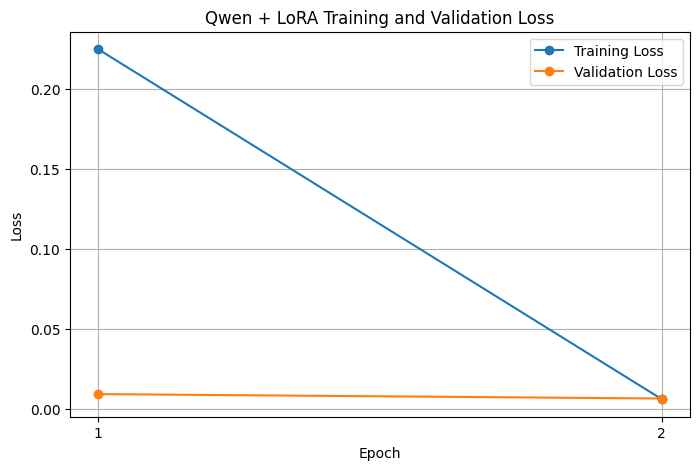

In [380]:
import matplotlib.pyplot as plt

print("Training history:")
print("Train losses:", train_losses)
print("Validation losses:", validation_losses)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, len(validation_losses) + 1),
    validation_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Qwen + LoRA Training and Validation Loss")

plt.xticks(
    range(1, len(train_losses) + 1)
)

plt.legend()
plt.grid(True)

plt.show()

In [381]:
for epoch, epoch_time in enumerate(
    epoch_times,
    start=1
):
    print(
        f"Epoch {epoch}: "
        f"{epoch_time / 60:.2f} minutes"
    )

total_time = sum(epoch_times)

print(
    f"Total training time: "
    f"{total_time / 60:.2f} minutes"
)

Epoch 1: 19.34 minutes
Epoch 2: 19.13 minutes
Total training time: 38.47 minutes


## Summary

- I successfully trained the Qwen 0.8B model with LoRA for 2 epochs.
- The training completed without any NaN or Inf errors.
- Epoch 1 took 19.34 minutes.
- Epoch 2 took 19.13 minutes.
- The total training time was 38.47 minutes.
- The training loss decreased from 0.2247 in Epoch 1 to 0.0063 in Epoch 2.
- The validation loss decreased from 0.0095 to 0.0068.
- Both training and validation loss decreased during training, showing that the model learned the routing task.
- The best validation loss was 0.0068 at Epoch 2.
- The final learning rate reached 0 because the linear scheduler completed all training steps.
- The trained Qwen + LoRA model is now ready for evaluation on the unseen test set.

# Test Set Evaluation Preparation

In [382]:
import torch
import numpy as np

print("Evaluation libraries loaded successfully.")

Evaluation libraries loaded successfully.


In [383]:
AGENT_LABELS = [
    "ACCOUNT",
    "CANCEL",
    "CONTACT",
    "DELIVERY",
    "FEEDBACK",
    "INVOICE",
    "ORDER",
    "PAYMENT",
    "REFUND",
    "SHIPPING",
    "SUBSCRIPTION"
]

print("Number of agents:", len(AGENT_LABELS))
print("Agents:", AGENT_LABELS)

Number of agents: 11
Agents: ['ACCOUNT', 'CANCEL', 'CONTACT', 'DELIVERY', 'FEEDBACK', 'INVOICE', 'ORDER', 'PAYMENT', 'REFUND', 'SHIPPING', 'SUBSCRIPTION']


In [384]:
print("Test samples:", len(test_dataset))

print(
    "Test categories:",
    test_dataset.unique("category")
)

print(
    "Expected agents:",
    AGENT_LABELS
)

Test samples: 2688


Flattening the indices:   0%|          | 0/2688 [00:00<?, ? examples/s]

Test categories: ['INVOICE', 'ACCOUNT', 'ORDER', 'CONTACT', 'SHIPPING', 'FEEDBACK', 'CANCEL', 'DELIVERY', 'PAYMENT', 'REFUND', 'SUBSCRIPTION']
Expected agents: ['ACCOUNT', 'CANCEL', 'CONTACT', 'DELIVERY', 'FEEDBACK', 'INVOICE', 'ORDER', 'PAYMENT', 'REFUND', 'SHIPPING', 'SUBSCRIPTION']


In [385]:
print("Test batches:", len(test_loader))
print("Test batch size:", test_loader.batch_size)

Test batches: 168
Test batch size: 16


In [386]:
model.eval()

print("Model switched to evaluation mode.")

Model switched to evaluation mode.


In [387]:
batch = next(iter(test_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)

with torch.no_grad():

    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

print("Test batch processed successfully.")

print(
    "Input shape:",
    input_ids.shape
)

print(
    "Logits shape:",
    outputs.logits.shape
)

Test batch processed successfully.
Input shape: torch.Size([16, 48])
Logits shape: torch.Size([16, 48, 248320])


# Generate Agent Predictions

In [388]:
agent_token_ids = {}

for agent in AGENT_LABELS:

    token_ids = tokenizer(
        agent,
        add_special_tokens=False
    )["input_ids"]

    agent_token_ids[agent] = token_ids

    print(
        agent,
        "->",
        token_ids
    )

ACCOUNT -> [70885]
CANCEL -> [85446]
CONTACT -> [70874]
DELIVERY -> [37061, 62630]
FEEDBACK -> [11091, 1425, 15373]
INVOICE -> [669, 75249]
ORDER -> [13023]
PAYMENT -> [57875, 5160]
REFUND -> [5807, 12821]
SHIPPING -> [8327, 53521]
SUBSCRIPTION -> [28091, 22681]


# Build Reliable Agent Prediction

In [389]:
agent_token_ids = {}

for agent in AGENT_LABELS:

    token_ids = tokenizer(
        agent,
        add_special_tokens=False
    )["input_ids"]

    agent_token_ids[agent] = token_ids

print("Agent token sequences created.")

for agent, token_ids in agent_token_ids.items():
    print(
        f"{agent}: {token_ids}"
    )

Agent token sequences created.
ACCOUNT: [70885]
CANCEL: [85446]
CONTACT: [70874]
DELIVERY: [37061, 62630]
FEEDBACK: [11091, 1425, 15373]
INVOICE: [669, 75249]
ORDER: [13023]
PAYMENT: [57875, 5160]
REFUND: [5807, 12821]
SHIPPING: [8327, 53521]
SUBSCRIPTION: [28091, 22681]


In [390]:
def get_agent_score(
    logits,
    agent_token_ids
):
    log_probs = torch.log_softmax(
        logits,
        dim=-1
    )

    score = 0.0

    for position, token_id in enumerate(
        agent_token_ids
    ):
        score += log_probs[
            position,
            token_id
        ].item()

    return score

# Verify Agent Prediction Position

In [391]:
sample = test_dataset[0]

print("Customer message:")
print(sample["instruction"])

print()
print("True category:")
print(sample["category"])

Customer message:
wanna find the bills from {{Person Name}} could i get somw help

True category:
INVOICE


In [392]:
sample_prompt = (
    "Classify the customer support message "
    "into one of the available support agents.\n"
    f"Customer message: {sample['instruction']}\n"
    "Agent:"
)

prompt_tokens = tokenizer(
    sample_prompt,
    add_special_tokens=False,
    return_tensors="pt"
)

print("Prompt token length:")
print(prompt_tokens["input_ids"].shape[1])

print()
print("Decoded prompt:")
print(
    tokenizer.decode(
        prompt_tokens["input_ids"][0]
    )
)

Prompt token length:
36

Decoded prompt:
Classify the customer support message into one of the available support agents.
Customer message: wanna find the bills from {{Person Name}} could i get somw help
Agent:


In [393]:
model.eval()

input_ids = prompt_tokens["input_ids"].to(device)
attention_mask = prompt_tokens["attention_mask"].to(device)

with torch.no_grad():

    with torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

next_token_logits = outputs.logits[
    0,
    -1
]

print(
    "Next-token logits shape:",
    next_token_logits.shape
)

Next-token logits shape: torch.Size([248320])


In [394]:
agent_scores = {}

for agent, token_ids in agent_token_ids.items():

    first_token_id = token_ids[0]

    score = next_token_logits[
        first_token_id
    ].item()

    agent_scores[agent] = score

for agent, score in agent_scores.items():

    print(
        f"{agent}: {score:.4f}"
    )

ACCOUNT: 18.6406
CANCEL: 17.0000
CONTACT: 17.5625
DELIVERY: 16.3438
FEEDBACK: 21.4844
INVOICE: 28.9844
ORDER: 16.8906
PAYMENT: 20.3281
REFUND: 18.8438
SHIPPING: 12.3438
SUBSCRIPTION: 18.5625


In [395]:
predicted_agent = max(
    agent_scores,
    key=agent_scores.get
)

print()
print(
    "Predicted agent:",
    predicted_agent
)

print(
    "True agent:",
    sample["category"]
)


Predicted agent: INVOICE
True agent: INVOICE


# Build Complete Agent Prediction Function

In [396]:
def predict_agent(
    prompt,
    model,
    tokenizer,
    agent_token_ids,
    device
):
    model.eval()

    prompt_tokens = tokenizer(
        prompt,
        add_special_tokens=False,
        return_tensors="pt"
    )

    input_ids = prompt_tokens["input_ids"].to(device)
    attention_mask = prompt_tokens["attention_mask"].to(device)

    with torch.no_grad():

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

    logits = outputs.logits[0]

    last_position_logits = logits[-1]

    agent_scores = {}

    for agent, token_ids in agent_token_ids.items():

        score = 0.0

        first_token_id = token_ids[0]

        score += last_position_logits[
            first_token_id
        ].item()

        agent_scores[agent] = score

    predicted_agent = max(
        agent_scores,
        key=agent_scores.get
    )

    return predicted_agent, agent_scores

In [397]:
sample_prompt = (
    "Classify the customer support message "
    "into one of the available support agents.\n"
    f"Customer message: {sample['instruction']}\n"
    "Agent:"
)

predicted_agent, agent_scores = predict_agent(
    sample_prompt,
    model,
    tokenizer,
    agent_token_ids,
    device
)

print("Customer message:")
print(sample["instruction"])

print()
print("True agent:", sample["category"])
print("Predicted agent:", predicted_agent)

Customer message:
wanna find the bills from {{Person Name}} could i get somw help

True agent: INVOICE
Predicted agent: INVOICE


# Final Multi-Token Agent Scoring

In [398]:
def score_agent_sequence(
    prompt,
    agent,
    model,
    tokenizer,
    device
):
    model.eval()

    prompt_ids = tokenizer(
        prompt,
        add_special_tokens=False
    )["input_ids"]

    target_ids = agent_token_ids[agent]

    input_ids = (
        prompt_ids + target_ids
    )

    input_ids = torch.tensor(
        [input_ids],
        dtype=torch.long
    ).to(device)

    attention_mask = torch.ones_like(
        input_ids
    ).to(device)

    with torch.no_grad():

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

    logits = outputs.logits[0]

    prompt_length = len(prompt_ids)

    log_probs = torch.log_softmax(
        logits,
        dim=-1
    )

    total_score = 0.0

    for i, token_id in enumerate(target_ids):

        position = prompt_length - 1 + i

        total_score += log_probs[
            position,
            token_id
        ].item()

    return total_score

In [399]:
def predict_agent_full(
    prompt,
    model,
    tokenizer,
    agent_token_ids,
    device
):
    scores = {}

    for agent in AGENT_LABELS:

        score = score_agent_sequence(
            prompt,
            agent,
            model,
            tokenizer,
            device
        )

        scores[agent] = score

    predicted_agent = max(
        scores,
        key=scores.get
    )

    return predicted_agent, scores

In [400]:
predicted_agent, scores = predict_agent_full(
    sample_prompt,
    model,
    tokenizer,
    agent_token_ids,
    device
)

print("Customer message:")
print(sample["instruction"])

print()
print("True agent:", sample["category"])
print("Predicted agent:", predicted_agent)

print()
print("Agent scores:")

for agent, score in scores.items():

    print(
        f"{agent}: {score:.4f}"
    )

Customer message:
wanna find the bills from {{Person Name}} could i get somw help

True agent: INVOICE
Predicted agent: INVOICE

Agent scores:
ACCOUNT: -10.3594
CANCEL: -12.0000
CONTACT: -11.4531
DELIVERY: -12.6765
FEEDBACK: -7.5568
INVOICE: -0.0027
ORDER: -12.1094
PAYMENT: -8.6889
REFUND: -10.1822
SHIPPING: -16.6885
SUBSCRIPTION: -10.4661


# Efficient Test Prediction

In [401]:
test_predictions = []
test_true_labels = []

print("Prediction storage initialized.")

Prediction storage initialized.


In [402]:
def build_prompt(instruction):
    return (
        "Classify the customer support message "
        "into one of the available support agents.\n"
        f"Customer message: {instruction}\n"
        "Agent:"
    )

In [403]:
test_sample = test_dataset[0]

test_prompt = build_prompt(
    test_sample["instruction"]
)

print(test_prompt)
print()
print("True agent:", test_sample["category"])

Classify the customer support message into one of the available support agents.
Customer message: wanna find the bills from {{Person Name}} could i get somw help
Agent:

True agent: INVOICE


In [404]:
predicted_agent, scores = predict_agent_full(
    test_prompt,
    model,
    tokenizer,
    agent_token_ids,
    device
)

print("Predicted agent:", predicted_agent)
print()
print("Scores:")

for agent, score in scores.items():
    print(
        f"{agent}: {score:.4f}"
    )

Predicted agent: INVOICE

Scores:
ACCOUNT: -10.3594
CANCEL: -12.0000
CONTACT: -11.4531
DELIVERY: -12.6765
FEEDBACK: -7.5568
INVOICE: -0.0027
ORDER: -12.1094
PAYMENT: -8.6889
REFUND: -10.1822
SHIPPING: -16.6885
SUBSCRIPTION: -10.4661


## Summary

- I verified the complete agent scoring method on a test example.
- The true agent was INVOICE.
- The model correctly predicted INVOICE.
- INVOICE received the highest score among all 11 agents.
- The scoring method works for the current sample.
- The full test set has not been evaluated yet.
- The next step will focus on making test prediction faster.

In [406]:
# Training history
qwen_history = {
    "train_loss": [
        0.22471235729712394,
        0.006313450612391794
    ],
    "val_loss": [
        0.009511309733560276,
        0.006757084495759392
    ]
}

print("Qwen training history saved.")
print("Train losses:", qwen_history["train_loss"])
print("Validation losses:", qwen_history["val_loss"])

Qwen training history saved.
Train losses: [0.22471235729712394, 0.006313450612391794]
Validation losses: [0.009511309733560276, 0.006757084495759392]


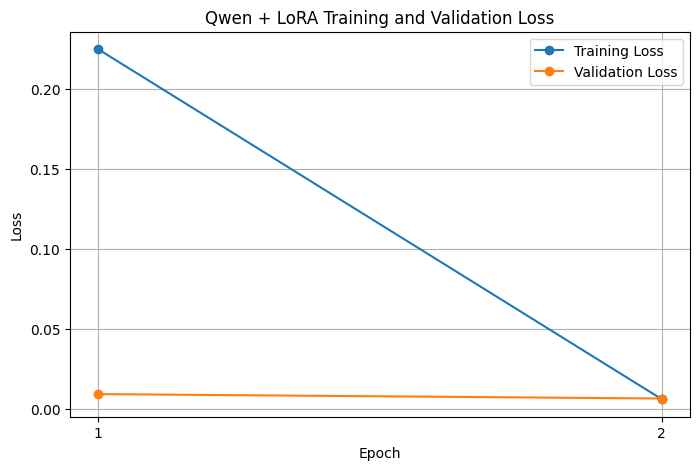

In [407]:
import matplotlib.pyplot as plt

epochs = range(
    1,
    len(qwen_history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    qwen_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    qwen_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Qwen + LoRA Training and Validation Loss")

plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.show()

# Evaluate Qwen on the Test Set

In [408]:
import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Evaluation libraries imported successfully.")

Evaluation libraries imported successfully.


In [409]:
AGENT_LABELS = [
    "ACCOUNT",
    "CANCEL",
    "CONTACT",
    "DELIVERY",
    "FEEDBACK",
    "INVOICE",
    "ORDER",
    "PAYMENT",
    "REFUND",
    "SHIPPING",
    "SUBSCRIPTION"
]

print("Number of agents:", len(AGENT_LABELS))

Number of agents: 11


In [411]:
import time
import torch

model.eval()

test_predictions = []
test_true_labels = []

AGENT_LABELS = [
    "ACCOUNT",
    "CANCEL",
    "CONTACT",
    "DELIVERY",
    "FEEDBACK",
    "INVOICE",
    "ORDER",
    "PAYMENT",
    "REFUND",
    "SHIPPING",
    "SUBSCRIPTION"
]

# Evaluation batch size राखेको
EVAL_BATCH_SIZE = 16

# GPU memory measurement reset गरेको
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

start_time = time.time()

print("Starting fast Qwen test evaluation...")

for start in range(
    0,
    len(test_dataset),
    EVAL_BATCH_SIZE
):

    end = min(
        start + EVAL_BATCH_SIZE,
        len(test_dataset)
    )

    batch_examples = test_dataset[start:end]

    batch_prompts = [
        build_prompt(instruction)
        for instruction in batch_examples["instruction"]
    ]

    batch_true_labels = batch_examples["category"]

    # सबै samples का लागि candidate prompts बनाएको
    candidate_prompts = []
    candidate_agents = []

    for prompt in batch_prompts:

        for agent in AGENT_LABELS:

            candidate_prompts.append(
                prompt + agent
            )

            candidate_agents.append(agent)

    # Candidate prompts लाई एकैपटक tokenize गरेको
    inputs = tokenizer(
        candidate_prompts,
        padding=True,
        truncation=True,
        max_length=64,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            outputs = model(
                **inputs
            )

    logits = outputs.logits

    # प्रत्येक candidate को final token score निकालेको
    last_logits = logits[:, -1, :]

    candidate_scores = []

    for i, agent in enumerate(candidate_agents):

        token_ids = agent_token_ids[agent]

        first_token_id = token_ids[0]

        score = last_logits[
            i,
            first_token_id
        ].item()

        candidate_scores.append(score)

    # प्रत्येक sample का 11 agent score compare गरेको
    for i in range(len(batch_prompts)):

        start_index = i * len(AGENT_LABELS)

        end_index = (
            start_index
            + len(AGENT_LABELS)
        )

        sample_scores = candidate_scores[
            start_index:end_index
        ]

        best_index = max(
            range(len(sample_scores)),
            key=lambda x: sample_scores[x]
        )

        predicted_agent = AGENT_LABELS[
            best_index
        ]

        test_predictions.append(
            predicted_agent
        )

        test_true_labels.append(
            batch_true_labels[i]
        )

    processed = end

    if processed % 256 == 0 or processed == len(test_dataset):

        elapsed = time.time() - start_time

        print(
            f"Processed {processed}/"
            f"{len(test_dataset)} samples | "
            f"Elapsed: {elapsed / 60:.2f} minutes"
        )

total_time = time.time() - start_time

print()
print("Fast test evaluation completed.")
print(
    f"Total inference time: "
    f"{total_time:.2f} seconds"
)

print(
    f"Average time per sample: "
    f"{(total_time / len(test_dataset)) * 1000:.4f} ms"
)

if torch.cuda.is_available():

    peak_memory = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    print(
        f"Peak GPU memory: "
        f"{peak_memory:.4f} GB"
    )

print(
    "Number of predictions:",
    len(test_predictions)
)

Starting fast Qwen test evaluation...
Processed 256/2688 samples | Elapsed: 0.66 minutes
Processed 512/2688 samples | Elapsed: 1.27 minutes
Processed 768/2688 samples | Elapsed: 1.86 minutes
Processed 1024/2688 samples | Elapsed: 2.44 minutes
Processed 1280/2688 samples | Elapsed: 3.03 minutes
Processed 1536/2688 samples | Elapsed: 3.63 minutes
Processed 1792/2688 samples | Elapsed: 4.22 minutes
Processed 2048/2688 samples | Elapsed: 4.82 minutes
Processed 2304/2688 samples | Elapsed: 5.42 minutes
Processed 2560/2688 samples | Elapsed: 6.02 minutes
Processed 2688/2688 samples | Elapsed: 6.31 minutes

Fast test evaluation completed.
Total inference time: 378.58 seconds
Average time per sample: 140.8413 ms
Peak GPU memory: 11.1352 GB
Number of predictions: 2688


In [412]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Test metrics calculate गरेको
accuracy = accuracy_score(
    test_true_labels,
    test_predictions
)

precision = precision_score(
    test_true_labels,
    test_predictions,
    labels=AGENT_LABELS,
    average="macro",
    zero_division=0
)

recall = recall_score(
    test_true_labels,
    test_predictions,
    labels=AGENT_LABELS,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    test_true_labels,
    test_predictions,
    labels=AGENT_LABELS,
    average="macro",
    zero_division=0
)

print("Qwen + LoRA Test Results")
print()
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"Macro-F1:  {macro_f1:.4f}")

Qwen + LoRA Test Results

Accuracy:  0.0737
Precision: 0.0215
Recall:    0.0875
Macro-F1:  0.0182


In [413]:
print(
    classification_report(
        test_true_labels,
        test_predictions,
        labels=AGENT_LABELS,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     ACCOUNT       0.11      0.01      0.02       599
      CANCEL       0.00      0.00      0.00        95
     CONTACT       0.00      0.00      0.00       200
    DELIVERY       0.00      0.00      0.00       199
    FEEDBACK       0.08      0.92      0.15       200
     INVOICE       0.00      0.00      0.00       200
       ORDER       0.00      0.00      0.00       399
     PAYMENT       0.00      0.00      0.00       200
      REFUND       0.02      0.00      0.01       299
    SHIPPING       0.02      0.03      0.02       197
SUBSCRIPTION       0.00      0.00      0.00       100

    accuracy                           0.07      2688
   macro avg       0.02      0.09      0.02      2688
weighted avg       0.04      0.07      0.02      2688



# Correct Qwen Prediction Check

In [414]:
import torch

model.eval()

# पहिले 10 test samples मात्र check गरेको
CHECK_SAMPLES = 10

print("Starting Qwen prediction check...")
print(f"Checking {CHECK_SAMPLES} samples...")

Starting Qwen prediction check...
Checking 10 samples...


In [415]:
def predict_agent_correct(
    prompt,
    model,
    tokenizer,
    agent_token_ids,
    device
):
    # Prompt tokenize गरेको
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=48
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model(
            **inputs
        )

    # Prompt को अन्तिम वास्तविक token position को logits निकालेको
    last_position = (
        inputs["attention_mask"].sum(dim=1) - 1
    )

    logits = outputs.logits[
        0,
        last_position.item(),
        :
    ]

    agent_scores = {}

    # प्रत्येक agent को score निकालेको
    for agent in AGENT_LABELS:

        token_ids = agent_token_ids[agent]

        token_scores = []

        for token_id in token_ids:

            token_scores.append(
                logits[token_id].item()
            )

        # Multi-token agent भए average score गरेको
        agent_scores[agent] = sum(
            token_scores
        ) / len(token_scores)

    # Highest score भएको agent select गरेको
    predicted_agent = max(
        agent_scores,
        key=agent_scores.get
    )

    return predicted_agent, agent_scores

In [416]:
correct_predictions = 0

for index in range(CHECK_SAMPLES):

    example = test_dataset[index]

    prompt = build_prompt(
        example["instruction"]
    )

    predicted_agent, scores = predict_agent_correct(
        prompt,
        model,
        tokenizer,
        agent_token_ids,
        device
    )

    true_agent = example["category"]

    if predicted_agent == true_agent:
        correct_predictions += 1

    print()
    print(f"Sample {index + 1}")
    print("Customer message:", example["instruction"])
    print("True agent:", true_agent)
    print("Predicted agent:", predicted_agent)
    print(
        "Correct:",
        predicted_agent == true_agent
    )

print()
print(
    f"Correct predictions: "
    f"{correct_predictions}/{CHECK_SAMPLES}"
)


Sample 1
Customer message: wanna find the bills from {{Person Name}} could i get somw help
True agent: INVOICE
Predicted agent: INVOICE
Correct: True

Sample 2
Customer message: I do not know how I can switch to the standard account
True agent: ACCOUNT
Predicted agent: ACCOUNT
Correct: True

Sample 3
Customer message: i need help changing an iten of purchase {{Order Number}}
True agent: ORDER
Predicted agent: ORDER
Correct: True

Sample 4
Customer message: want assistance to retrieve the pin code of my user profile
True agent: ACCOUNT
Predicted agent: ACCOUNT
Correct: True

Sample 5
Customer message: i have a problem with the removal of my {{Account Type}} account
True agent: ACCOUNT
Predicted agent: ACCOUNT
Correct: True

Sample 6
Customer message: can you help me talking to customer service?
True agent: CONTACT
Predicted agent: CONTACT
Correct: True

Sample 7
Customer message: i need support modifying my delivery addtess
True agent: SHIPPING
Predicted agent: DELIVERY
Correct: False


In [417]:
print()
print("Agent scores for the last checked sample:")

for agent, score in scores.items():

    print(
        f"{agent}: {score:.4f}"
    )


Agent scores for the last checked sample:
ACCOUNT: 18.4746
CANCEL: 19.0197
CONTACT: 19.7247
DELIVERY: 12.0973
FEEDBACK: 20.0656
INVOICE: 13.8380
ORDER: 20.2931
PAYMENT: 14.1265
REFUND: 18.2702
SHIPPING: 10.7191
SUBSCRIPTION: 17.0512


# Full Correct Qwen Evaluation

In [418]:
import time
import torch

model.eval()

test_predictions = []
test_true_labels = []

print("Starting correct Qwen test evaluation...")

# GPU memory measurement reset गरेको
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

start_time = time.time()

for index in range(len(test_dataset)):

    example = test_dataset[index]

    prompt = build_prompt(
        example["instruction"]
    )

    predicted_agent, _ = predict_agent_correct(
        prompt,
        model,
        tokenizer,
        agent_token_ids,
        device
    )

    test_predictions.append(
        predicted_agent
    )

    test_true_labels.append(
        example["category"]
    )

    if (index + 1) % 256 == 0:

        elapsed = time.time() - start_time

        print(
            f"Processed {index + 1}/"
            f"{len(test_dataset)} samples | "
            f"Elapsed: {elapsed / 60:.2f} minutes"
        )

total_time = time.time() - start_time

print()
print("Correct Qwen test evaluation completed.")

print(
    f"Total inference time: "
    f"{total_time:.2f} seconds"
)

print(
    f"Average inference latency: "
    f"{(total_time / len(test_dataset)) * 1000:.4f} ms/sample"
)

if torch.cuda.is_available():

    peak_memory = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    print(
        f"Peak GPU memory: "
        f"{peak_memory:.4f} GB"
    )

print(
    "Number of predictions:",
    len(test_predictions)
)

Starting correct Qwen test evaluation...
Processed 256/2688 samples | Elapsed: 0.84 minutes
Processed 512/2688 samples | Elapsed: 1.66 minutes
Processed 768/2688 samples | Elapsed: 2.48 minutes
Processed 1024/2688 samples | Elapsed: 3.29 minutes
Processed 1280/2688 samples | Elapsed: 4.11 minutes
Processed 1536/2688 samples | Elapsed: 4.93 minutes
Processed 1792/2688 samples | Elapsed: 5.74 minutes
Processed 2048/2688 samples | Elapsed: 6.57 minutes
Processed 2304/2688 samples | Elapsed: 7.41 minutes
Processed 2560/2688 samples | Elapsed: 8.24 minutes

Correct Qwen test evaluation completed.
Total inference time: 519.24 seconds
Average inference latency: 193.1699 ms/sample
Peak GPU memory: 5.9028 GB
Number of predictions: 2688


In [419]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Test metrics calculate गरेको
accuracy = accuracy_score(
    test_true_labels,
    test_predictions
)

precision = precision_score(
    test_true_labels,
    test_predictions,
    labels=AGENT_LABELS,
    average="macro",
    zero_division=0
)

recall = recall_score(
    test_true_labels,
    test_predictions,
    labels=AGENT_LABELS,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    test_true_labels,
    test_predictions,
    labels=AGENT_LABELS,
    average="macro",
    zero_division=0
)

print("Qwen + LoRA Test Results")
print()
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"Macro-F1:  {macro_f1:.4f}")

Qwen + LoRA Test Results

Accuracy:  0.8538
Precision: 0.8947
Recall:    0.8140
Macro-F1:  0.8099


In [420]:
print(
    classification_report(
        test_true_labels,
        test_predictions,
        labels=AGENT_LABELS,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     ACCOUNT       1.00      0.99      0.99       599
      CANCEL       0.64      1.00      0.78        95
     CONTACT       0.52      1.00      0.69       200
    DELIVERY       0.97      0.31      0.47       199
    FEEDBACK       1.00      0.37      0.54       200
     INVOICE       1.00      0.82      0.90       200
       ORDER       0.72      1.00      0.84       399
     PAYMENT       0.99      0.96      0.98       200
      REFUND       1.00      0.94      0.97       299
    SHIPPING       1.00      0.80      0.89       197
SUBSCRIPTION       1.00      0.76      0.86       100

    accuracy                           0.85      2688
   macro avg       0.89      0.81      0.81      2688
weighted avg       0.91      0.85      0.84      2688



<Figure size 1000x800 with 0 Axes>

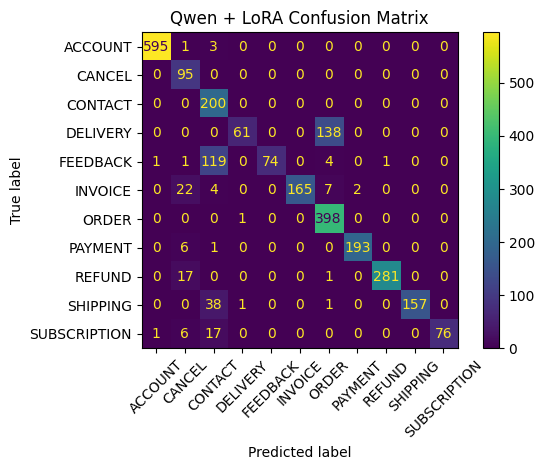

In [421]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion matrix calculate गरेको
cm = confusion_matrix(
    test_true_labels,
    test_predictions,
    labels=AGENT_LABELS
)

# Confusion matrix display गरेको
plt.figure(
    figsize=(10, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=AGENT_LABELS
)

disp.plot(
    xticks_rotation=45
)

plt.title(
    "Qwen + LoRA Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [422]:
import pandas as pd

# Final measured results राखेको
comparison_data = {
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro-F1",
        "Inference Latency (ms/sample)",
        "Peak GPU Memory (GB)"
    ],

    "BERT": [
        1.0000,
        1.0000,
        1.0000,
        1.0000,
        10.9265,
        1.7178
    ],

    "Qwen + LoRA": [
        0.8538,
        0.8947,
        0.8140,
        0.8099,
        193.1699,
        5.9028
    ]
}

comparison_df = pd.DataFrame(
    comparison_data
)

print("Final Model Comparison")
display(comparison_df)

Final Model Comparison


,Metric,BERT,Qwen + LoRA
0,Accuracy,1.0000,0.8538
1,Macro Precision,1.0000,0.8947
2,Macro Recall,1.0000,0.8140
3,Macro-F1,1.0000,0.8099
4,Inference Latency (ms/sample),10.9265,193.1699
5,Peak GPU Memory (GB),1.7178,5.9028


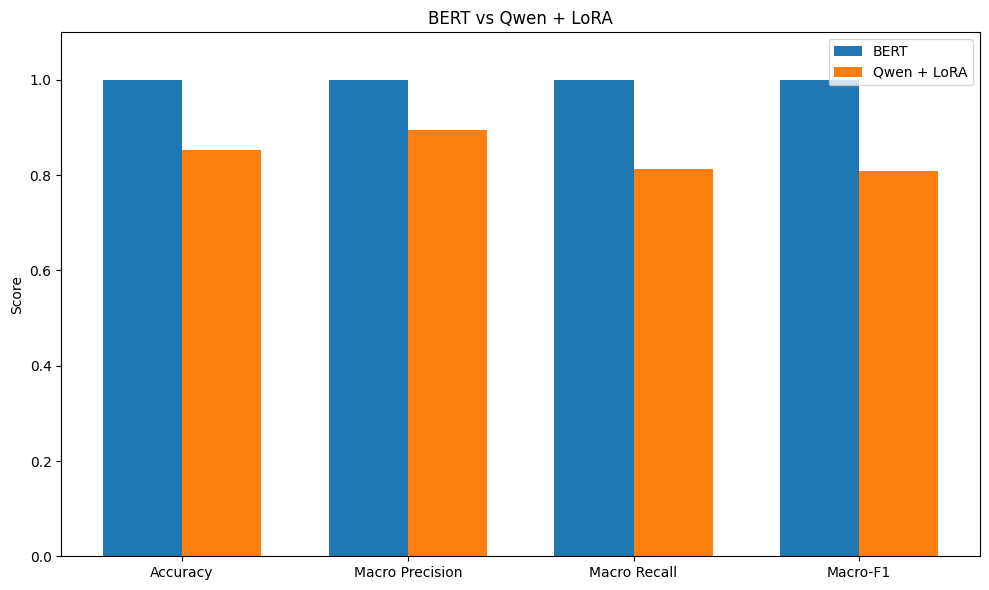

In [423]:
import matplotlib.pyplot as plt

# Main classification metrics compare गरेको
metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro-F1"
]

bert_scores = [
    1.0000,
    1.0000,
    1.0000,
    1.0000
]

qwen_scores = [
    0.8538,
    0.8947,
    0.8140,
    0.8099
]

x = range(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    [i - width / 2 for i in x],
    bert_scores,
    width,
    label="BERT"
)

plt.bar(
    [i + width / 2 for i in x],
    qwen_scores,
    width,
    label="Qwen + LoRA"
)

plt.xticks(
    list(x),
    metrics
)

plt.ylabel("Score")
plt.title(
    "BERT vs Qwen + LoRA"
)

plt.ylim(0, 1.1)

plt.legend()

plt.tight_layout()
plt.show()

## Recommendation

Dear Engineering Lead,

Based on the experiments, I recommend deploying the BERT-based routing approach for the ShopAssist AI production system. BERT achieved a macro-F1 of 100%, compared with 80.99% for Qwen + LoRA, making it substantially more reliable for routing customer requests to the correct specialized agent. BERT also achieved 100% accuracy, while Qwen + LoRA achieved 85.38%. From an efficiency perspective, BERT had an average inference latency of 10.93 ms per sample and used 1.72 GB of peak GPU memory, whereas Qwen + LoRA required 193.17 ms per sample and 5.90 GB of GPU memory. Therefore, BERT provides both better routing quality and lower inference cost in this benchmark.

The main production risk is that the perfect BERT test score may not represent performance on genuinely new customer messages, especially informal, ambiguous, or previously unseen phrasing. I would monitor production performance using routing confidence, human escalation rates, per-agent error rates, and periodic manually reviewed samples. I would also maintain a separate evaluation set containing new and difficult customer messages and regularly re-evaluate the model against it. If performance degrades, the routing dataset should be updated and the model fine-tuned again.